# Анализ лояльности пользователей Яндекс Афиши с помощью python
- Автор: Перепелюк Иван Александрович
- Дата: 31.01.2026

### Цели и задачи данного проекта
Цель проекта: изучить данные с действиями пользователей, проанализировать распределение данных, составить потрет пользователя, определить какие факторы влияют на повторное совершение покупки пользователем при помощи сервиса.

Задачи проекта:
- Получить данные из БД PostgreSQL;
- Ознакомиться с полученными данными, изучить их объём;
- Предобработать данные для дальнейшего анализа;
- Провести расчёт необходимых метрик, построить соответствующие графики;
- По полученным данным сделать выводы и предоставить бизнес-рекомендации.

### Описание данных
- user_id - уникальный идентификатор пользователя, совершившего заказ;
- device_type_canonical - тип устройства, с которого был оформлен заказ ( mobile - мобильные устройства, desktop - стационарные);
- order_id - уникальный идентификатор заказа;
- order_dt - дата создания заказа;
- order_ts - дата и время создания заказа;
- currency_code - валюта оплаты;
- revenue - выручка от заказа;
- tickets_count - количество купленных билетов;
- days_since_prev - количество дней от предыдущей покупки пользователя, для пользователей с одной покупкой - значение пропущено;
- event_id - уникальный идентификатор мероприятия;
- service_name - название билетного оператора;
- event_type_main - основной тип мероприятия (театральная постановка, концерт и так далее);
- region_name - название региона, в котором прошло мероприятие;
- city_name - название города, в котором прошло мероприятие.

### Содержимое проекта
1. Загрузка данных и их предобработка

 1.1 Выгрузка данных в датафрейм

 1.2 Общая информация о полученных данных

2. Предобработка данных

 2.1 Приведение показателя выручки к единой валюте

 2.2 Общая предобработка данных

 2.3 Промежуточный вывод

3. Создание профиля пользователя

 3.1 Построение профиля для каждого пользователя

 3.2 Предобработка показателей профилей пользователей

 3.3 Промежуточный вывод

4. Исследовательский анализ данных

 4.1 Исследование признаков первого заказа и их связи с возвращением на платформу

 4.2 Исследование поведения пользователей через показатели выручки и состава заказа

 4.3 Исследование временных характеристик первого заказа и их влияния на повторные покупки

 4.4 Корреляционный анализ количества покупок и признаков пользователя

5. Общие выводы и рекомендации

## 1. Загрузка данных и их предобработка
### 1.1 Выгрузка данных в датафрейм

In [1]:
# Импортируем необходимые библиотеки

# Библиотеки для работы с данными
import pandas as pd
from sqlalchemy import create_engine

# Библиотеки для построения графиков
import matplotlib.pyplot as plt
import seaborn as sns

# Библиотеки для математических вычислений
import numpy as np


# Библиотека для расчёта корреляции
from phik import phik_matrix

In [2]:
# Параметры подключения читаются из переменных окружения (файл .env, см. .env.example)
import os

from dotenv import load_dotenv
from sqlalchemy.engine import URL

load_dotenv()

# Строка подключения собирается через URL.create: спецсимволы пароля экранируются автоматически
connection_url = URL.create(
    'postgresql+psycopg2',
    username=os.environ['DB_USER'],
    password=os.environ['DB_PASSWORD'],
    host=os.environ['DB_HOST'],
    port=int(os.environ.get('DB_PORT', 6432)),
    database=os.environ['DB_NAME_AFISHA'],
)
engine = create_engine(connection_url)

# Пишем SQL-запрос, с помощью которого извлечём необходимые данные
query = '''
SELECT
      user_id,
      device_type_canonical,
      order_id,
      created_dt_msk AS order_dt,
      created_ts_msk AS order_ts,
      currency_code,
      revenue,
      tickets_count,
      COALESCE(created_dt_msk::DATE - LAG(created_dt_msk::DATE) OVER(PARTITION BY user_id ORDER BY created_dt_msk), NULL) AS days_since_prev,
      p.event_id,
      e.event_name_code AS event_name,
      e.event_type_main,
      p.service_name,
      c.city_name,
      r.region_name
FROM afisha.purchases p
LEFT JOIN afisha.events e ON p.event_id = e.event_id
LEFT JOIN afisha.city c ON e.city_id = c.city_id
LEFT JOIN afisha.regions r ON c.region_id = r.region_id
WHERE (p.device_type_canonical = 'mobile' OR p.device_type_canonical = 'desktop') AND e.event_type_main <> 'фильм'
ORDER BY user_id;
'''

# При помощи библиотеки pandas загружаем данные из БД в датафрейм
df = pd.read_sql_query(query, con=engine)

# Выводим первые пять строк датафрейма, дабы убедиться, что он загружен
display(df.head())

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,city_name,region_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Глиногорск,Каменевский регион
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Глиногорск,Каменевский регион
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Глиногорск,Каменевский регион
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Озёрск,Североярская область
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Родниковецк,Озернинский край


Данные успешно загружены в датафрейм 'df'. Далее исследуем полученный датафрейм на корректность данных, проведём предобработку и оптимизацию типов хранимых данных.

### 1.2 Общая информация о полученных данных

In [3]:
# Выведем количество строк и столбцов полученного датафрейма
print(f'Всего в датафрейме {df.shape[0]} строк и {df.shape[1]} столбцов.')

# Выведем краткую сводку о данных датафрейма
print('\nИнформация о датафрейме:')
print(df.info())

# Выведем первые пять строк датафрейма
print('\nПервые пять строк датафрейма:')
display(df.head())

# Статистика по числовым признакам
print('\nСтатистика датафрейма по числовым признакам:')
display(df.describe())

Всего в датафрейме 290611 строк и 15 столбцов.

Информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 n

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,city_name,region_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Глиногорск,Каменевский регион
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Глиногорск,Каменевский регион
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Глиногорск,Каменевский регион
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Озёрск,Североярская область
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Родниковецк,Озернинский край



Статистика датафрейма по числовым признакам:


,order_id,revenue,tickets_count,days_since_prev,event_id
count,2.906110e+05,290611.000000,290611.000000,268678.000000,290611.000000
mean,4.326225e+06,625.584360,2.754311,3.222381,438019.834992
std,2.497551e+06,1227.693064,1.170620,11.350509,147423.078841
min,1.000000e+00,-90.760000,1.000000,0.000000,4436.000000
25%,2.163618e+06,116.850000,2.000000,0.000000,361772.000000
50%,4.326366e+06,356.010000,3.000000,0.000000,498275.000000
75%,6.488330e+06,810.130000,4.000000,1.000000,546287.000000
max,8.653108e+06,81174.540000,57.000000,148.000000,592325.000000


Общая информация о датафрейме 'df':
- 290611 строк, 15 столбцов;
- 8 столбцов типа 'object';
- 3 стобца типа 'inf64';
- 2 столбца типа 'float64';
- 2 столбца типа datetime64;
- Пропуски присутствуют только в столбце 'days_since_prev', этого следовало ожидать, так как в SQL-запросе NULL значение данного поля образовалось при первом заказе пользователя.

Что важно сделать на этапе предобработки данных:
- Изучить пропуски в столбце 'days_since_prev';
- Проверить данные в поле 'revenue': отрицательные значения, сильный размах между макс. и мин. значениями;
- Размах значений в поле 'tickets_count';
- Привести показатель выручки к единой единице измерения - Российским рублям;
- Изучить датасет на наличие явных и неявных дубликатов.

## 2. Предобработка данных
### 2.1 Приведение показателя выручки к единой валюте

In [4]:
# Создаем копию основго датафрейма для безопасного перевода валюты и предобработки данных
df2 = df.copy()

# Загружаем данные о курсе тенге
exc_df = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')

# Для удобства переименуем названия столбцов
exc_df.columns = ['exc_date', 'nominal', 'exc_rate', 'currency']

# Преобразуем дату к типу 'datetime'
exc_df['exc_date'] = pd.to_datetime(exc_df['exc_date'])

# Объединяем df2 и exc_df по полю с датой
df2 = df2.merge(exc_df[['exc_date', 'exc_rate']],
                left_on='order_dt',
                right_on='exc_date',
                how='left')

# Создаём столбец с показателем цены в рублях (переводим kzt -> rub)
# Если kzt - конвертируем (курс дан для 100 тенге), если rub - оставляем как есть
df2['revenue_rub'] = df2.apply(
    lambda row: row['revenue'] * row['exc_rate'] / 100 if row['currency_code'] == 'kzt'
    else row['revenue'],
    axis=1
)

# Удалить временные столбцы
df2 = df2.drop(columns=['exc_date', 'exc_rate'])

# Проверка результата
print("Результат перевода тенге в рубли:")
print(f"Строк с kzt: {(df2['currency_code'] == 'kzt').sum()}")
print(f"Строк с rub: {(df2['currency_code'] == 'rub').sum()}")
print(f"Пропусков в revenue_rub: {df2['revenue_rub'].isnull().sum()}")
print("\nПример конвертации:")
print(df2[['order_dt', 'currency_code', 'revenue', 'revenue_rub']].head(100))
print("\nСтатистика по revenue_rub:")
print(df2['revenue_rub'].describe())

Результат перевода тенге в рубли:
Строк с kzt: 5069
Строк с rub: 285542
Пропусков в revenue_rub: 0

Пример конвертации:
     order_dt currency_code  revenue  revenue_rub
0  2024-08-20           rub  1521.94  1521.940000
1  2024-07-23           rub   289.45   289.450000
2  2024-10-06           rub  1258.57  1258.570000
3  2024-07-13           rub     8.49     8.490000
4  2024-10-04           rub  1390.41  1390.410000
..        ...           ...      ...          ...
95 2024-07-21           rub    47.56    47.560000
96 2024-09-09           kzt   328.77    61.148261
97 2024-09-21           rub   103.20   103.200000
98 2024-09-10           rub   824.54   824.540000
99 2024-09-10           rub   618.41   618.410000

[100 rows x 4 columns]

Статистика по revenue_rub:
count    290611.000000
mean        555.571987
std         875.498172
min         -90.760000
25%         113.970000
50%         351.140000
75%         802.050000
max       81174.540000
Name: revenue_rub, dtype: float64


In [5]:
# Выведем информацию о новом датафрейме с добавленным столбцов 'revenue_rub'
display(df2.head(3))

# Информация о новом датафрейме
print(df2.info())

# Статистика нового датафрейма
display(df2.describe())

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,city_name,region_name,revenue_rub
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Глиногорск,Каменевский регион,1521.94
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Глиногорск,Каменевский регион,289.45
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Глиногорск,Каменевский регион,1258.57


<class 'pandas.core.frame.DataFrame'>
Int64Index: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

,order_id,revenue,tickets_count,days_since_prev,event_id,revenue_rub
count,2.906110e+05,290611.000000,290611.000000,268678.000000,290611.000000,290611.000000
mean,4.326225e+06,625.584360,2.754311,3.222381,438019.834992,555.571987
std,2.497551e+06,1227.693064,1.170620,11.350509,147423.078841,875.498172
min,1.000000e+00,-90.760000,1.000000,0.000000,4436.000000,-90.760000
25%,2.163618e+06,116.850000,2.000000,0.000000,361772.000000,113.970000
50%,4.326366e+06,356.010000,3.000000,0.000000,498275.000000,351.140000
75%,6.488330e+06,810.130000,4.000000,1.000000,546287.000000,802.050000
max,8.653108e+06,81174.540000,57.000000,148.000000,592325.000000,81174.540000


На данном этапе предобработки данных произвели перевод KZT в Российские рубли для расчёта метрик, результат данного этапа - новый датафрейм 'df2', который содержит столбец 'revenue_rub' с информацией о цене заказа в рублях.

### 2.2 Общая предобработка данных

Целью данного этапа являются следующие задачи:
- Проверка пропущенных значений;
- Оптимизация типов хранимых данных;
- Обработка ошибок в ключевых столбцах;
- Изучение распределения числовых данных.

In [6]:
# Изучим количество пропусков в каждом поле датафрейма
missing = df2.isna().sum()
missing_percent = (df2.isna().sum() * 100) / len(df2)

missingdf = pd.DataFrame({
    'Пропуски': missing,
    'Процент': missing_percent
})

display(missingdf)

,Пропуски,Процент
user_id,0,0.000000
device_type_canonical,0,0.000000
order_id,0,0.000000
order_dt,0,0.000000
order_ts,0,0.000000
currency_code,0,0.000000
revenue,0,0.000000
tickets_count,0,0.000000
days_since_prev,21933,7.547202
event_id,0,0.000000


Пропуски присутствуют только в поле 'days_since_prev', которое показывает сколько дней прошло с момента предыдущего заказа до даты последнего заказа. NULL - значения имеют практический смысл, они показывают, что пользователь совершил лишь 1 заказ, следовательно разница между датой текущего заказа и датой предыдудщего заказа (в днях) равна нулю.

In [7]:
# Преобразуем типы хранимых данных

# Оптимизация числовых столбцов
df2['order_id'] = df2['order_id'].astype('int32')
df2['tickets_count'] = df2['tickets_count'].astype('int8')
df2['event_id'] = df2['event_id'].astype('int32')

# Оптимизация столбца с датой
df2['order_dt'] = pd.to_datetime(df2['order_dt'].dt.date)

print(f"Размер датафрейма после оптимизации: {df2.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print("\nТипы данных после оптимизации:")
print(df2.dtypes)

Размер датафрейма после оптимизации: 212.49 MB

Типы данных после оптимизации:
user_id                          object
device_type_canonical            object
order_id                          int32
order_dt                 datetime64[ns]
order_ts                 datetime64[ns]
currency_code                    object
revenue                         float64
tickets_count                      int8
days_since_prev                 float64
event_id                          int32
event_name                       object
event_type_main                  object
service_name                     object
city_name                        object
region_name                      object
revenue_rub                     float64
dtype: object


После изменений некоторых типов данных получилось сократить объём занимаемой памяти датафреймом. Были проведены следующие имзенения:
 - 'order_id' с int64 -> int32;
 - 'tickets_count' с int64 -> int8
 - 'event_id' с int64 -> int32.

In [8]:
# Проверка на явные и неявные дубликаты

# Явные дубликаты в датафрейме (работаем с df2)
duplicates_full = df2.duplicated().sum()
print(f"Найдено явных дубликатов: {duplicates_full}")

if duplicates_full > 0:
    df2 = df2.drop_duplicates().copy()
    print(f"Размер датафрейма после удаления явных дубликатов: {len(df2)}")

# Неявные дубликаты

print("Ищем дубликаты заказов у одного пользователя в короткий промежуток времени")
print("Технические дубликаты.")

# Создаем вспомогательный датасет для проверки
df_check = df2.copy()

# Нормализуем строковые поля (регистр и пробелы)
for col in ['service_name', 'city_name', 'region_name',
            'device_type_canonical', 'currency_code', 'event_type_main']:
    df_check[f'{col}_norm'] = df_check[col].astype(str).str.strip().str.lower()

# Округляем время: варианты для проверки
df_check['order_minute'] = df_check['order_ts'].dt.floor('min')  # до минуты
df_check['order_5min'] = df_check['order_ts'].dt.floor('5min')   # до 5 минут
df_check['order_15min'] = df_check['order_ts'].dt.floor('15min') # до 15 минут

print(f"\nСозданы временные интервалы для проверки:")

# Разные варианты временных окон
time_windows = {
    '1 минута': ['order_minute'],
    '5 минут': ['order_5min'],
    '15 минут': ['order_15min']
}

for window_name, time_col in time_windows.items():
    # Поля для проверки дубликатов (включая время)
    check_cols = ['user_id', time_col[0], 'revenue_rub', 'tickets_count',
                 'service_name_norm', 'city_name_norm']

    # Ищем дубликаты
    dup_mask = df_check.duplicated(subset=check_cols, keep=False)
    dup_count = dup_mask.sum()

    if dup_count > 0:
        print(f"{window_name}: {dup_count:,} потенциальных дубликатов ({(dup_count/len(df_check))*100:.2f}%)")

        # Если нашли дубликаты - анализируем
        if window_name == '1 минута':  # Самые явные дубликаты
            print(f"\n   Анализ дубликатов в пределах {window_name}:")

            # Получаем индексы дубликатов
            dup_indices = df_check[dup_mask].index

            # Смотрим оригинальные записи
            dup_samples = df2.loc[dup_indices].sort_values(['user_id', 'order_dt'])

            # Показываем примеры
            print("   Примеры технических дубликатов:")
            example_groups = dup_samples.groupby('user_id').head(2)

            for user_id in example_groups['user_id'].unique()[:3]:  # 3 пользователя
                user_orders = dup_samples[dup_samples['user_id'] == user_id]
                print(f"\n   Пользователь {user_id}:")
                for _, row in user_orders.head(3).iterrows():
                    print(f"Идентификатор заказа: {row['order_id']}, время: {row['order_dt']}, "
                          f"сумма: {row['revenue_rub']:.2f}")

            # Принимаем решение
            dup_percentage = (dup_count / len(df_check)) * 100
            if dup_percentage < 3:  # Если меньше 3% - удаляем
                print(f"\n   Решение: удаляем {dup_count:,} дубликатов ({dup_percentage:.2f}%)")

                # Удаляем, оставляя первую запись
                df_before = df2.copy()

                # 1. Удаляем все дубликаты
                df2 = df2.drop(index=dup_indices)

                # 2. Добавляем order_minute в оригинальный df2 для drop_duplicates
                df2['order_minute_temp'] = df2['order_ts'].dt.floor('min')

                # 3. Удаляем дубликаты, оставляя первую запись
                df2 = df2.drop_duplicates(
                    subset=['user_id', 'order_minute_temp', 'revenue_rub', 'tickets_count'],
                    keep='first'
                ).copy()

                # 4. Удаляем временный столбец
                df2 = df2.drop(columns=['order_minute_temp'])

                # 5. Пересчитываем days_since_prev
                print("   Пересчитываем количество дней между текущим и предыдущим заказами")
                df2 = df2.sort_values(['user_id', 'order_dt'])
                df2['days_since_prev'] = df2.groupby('user_id')['order_dt'].diff().dt.days
                print(f"   Удалено: {len(df_before) - len(df2):,} записей")
            else:
                print(f"\nМного дубликатов ({dup_percentage:.2f}%)!")
                print("Требуется дополнительный анализ, оставляем дабы не потерять важную информацию.")
                df2['is_tech_duplicate'] = df2.index.isin(dup_indices)

            break  # Останавливаемся на первом найденном временном окне

# 3. ОЧИСТКА ПАМЯТИ
del df_check
print("\nВременный датафрейм удален")

print(f"\nИтоговый размер датафрейма: {len(df2):,} записей")

Найдено явных дубликатов: 0
Ищем дубликаты заказов у одного пользователя в короткий промежуток времени
Технические дубликаты.

Созданы временные интервалы для проверки:
1 минута: 6,392 потенциальных дубликатов (2.20%)

   Анализ дубликатов в пределах 1 минута:
   Примеры технических дубликатов:

   Пользователь 00fcd3ab0e5c558:
Идентификатор заказа: 865506, время: 2024-10-01 00:00:00, сумма: 240.32
Идентификатор заказа: 865361, время: 2024-10-01 00:00:00, сумма: 240.32

   Пользователь 0186f6e000b581c:
Идентификатор заказа: 5679100, время: 2024-10-10 00:00:00, сумма: 209.23
Идентификатор заказа: 5679013, время: 2024-10-10 00:00:00, сумма: 209.23

   Пользователь 019fa401ddb00aa:
Идентификатор заказа: 524379, время: 2024-07-28 00:00:00, сумма: 29.31
Идентификатор заказа: 6893852, время: 2024-07-28 00:00:00, сумма: 29.31
Идентификатор заказа: 2459317, время: 2024-09-11 00:00:00, сумма: 432.08

   Решение: удаляем 6,392 дубликатов (2.20%)
   Пересчитываем количество дней между текущим и п

In [9]:
# Изучаем отрицательные значения в поле revenue_rub
print('Анализ отрицательных показателей выручки')

negative_count = (df2['revenue_rub'] < 0).sum()
negative_pct = negative_count / len(df2) * 100

print(f"Отрицательных значений: {negative_count} ({negative_pct:.2f}%)")

if negative_count > 0:
    print("\nСтатистика по возвратам:")
    print(df2[df2['revenue_rub'] < 0]['revenue_rub'].describe())

    # Если меньше 1% - удаляем, если больше - анализируем
    if negative_pct < 1:
        df2 = df2[df2['revenue_rub'] >= 0].copy()
        print(f"\nУдалено {negative_count} возвратов")
    else:
        print("Много возвратов!")

Анализ отрицательных показателей выручки
Отрицательных значений: 377 (0.13%)

Статистика по возвратам:
count    377.000000
mean      -2.510690
std        5.088396
min      -90.760000
25%       -3.470000
50%       -1.580000
75%       -0.650000
max       -0.010000
Name: revenue_rub, dtype: float64

Удалено 377 возвратов


In [10]:
# Проверка категориальных данных

# Зададим массив со всеми категориальными полями в датафрейме
categorial_columns = ['device_type_canonical', 'currency_code', 'event_type_main',
                    'service_name', 'city_name', 'region_name']

# С помощью цикла выведем информацию о каждом категориальном столбце
for col in categorial_columns:
    print(f"СТОЛБЕЦ: {col}")

    # Общая информация
    print(f"Уникальных значений: {df2[col].nunique()}")
    print(f"Всего записей: {len(df2)}")

    # Все уникальные значения (если их немного)
    if df2[col].nunique() <= 40:
        print(f"\nВсе уникальные значения:")
        print(df2[col].unique())

    # Частотное распределение
    print(f"\nЧастотное распределение (топ-15):")
    value_counts = df2[col].value_counts()
    value_counts_pct = df2[col].value_counts(normalize=True) * 100
    freq_table = pd.DataFrame({
        'Значение': value_counts.index,
        'Количество': value_counts.values,
        'Процент': value_counts_pct.values.round(2)
    })
    print(freq_table.head(15).to_string(index=False))

    # Проверка на подозрительные значения
    print(f"\nПроверка на аномальные значения в столбце")

    # Пустые строки и пробелы
    empty_mask = df2[col].isin(['', ' ', '  '])
    if empty_mask.any():
        print(f"Пустых строк: {empty_mask.sum()}")

    # Значения типа null, None, nan в виде строк
    null_like = df2[col].astype(str).str.lower().isin(['null', 'none', 'nan', 'n/a', 'na'])
    if null_like.any():
        print(f"Строковых null-значений: {null_like.sum()}")

    # Проверка на лишние пробелы в начале/конце
    has_spaces = df2[col].astype(str).str.strip() != df2[col].astype(str)
    if has_spaces.any():
        print(f"Значений с лишними пробелами: {has_spaces.sum()}")

    # Проверка на смешанный регистр (возможные дубликаты)
    if df2[col].dtype == 'object':
        lower_unique = df2[col].str.lower().nunique()
        if lower_unique < df2[col].nunique():
            print(f"Возможные дубликаты из-за регистра: {df2[col].nunique() - lower_unique}")

    # Проверка на слишком длинные значения
    max_len = df2[col].astype(str).str.len().max()
    if max_len > 100:
        print(f"Максимальная длина значения: {max_len} символов")
        long_values = df2[df2[col].astype(str).str.len() > 100][col].unique()
        print(f"   Примеры: {long_values[:3]}")

    print("\n")

СТОЛБЕЦ: device_type_canonical
Уникальных значений: 2
Всего записей: 283829

Все уникальные значения:
['mobile' 'desktop']

Частотное распределение (топ-15):
Значение  Количество  Процент
  mobile      227969    80.32
 desktop       55860    19.68

Проверка на аномальные значения в столбце


СТОЛБЕЦ: currency_code
Уникальных значений: 2
Всего записей: 283829

Все уникальные значения:
['rub' 'kzt']

Частотное распределение (топ-15):
Значение  Количество  Процент
     rub      278843    98.24
     kzt        4986     1.76

Проверка на аномальные значения в столбце


СТОЛБЕЦ: event_type_main
Уникальных значений: 7
Всего записей: 283829

Все уникальные значения:
['театр' 'выставки' 'другое' 'стендап' 'концерты' 'спорт' 'ёлки']

Частотное распределение (топ-15):
Значение  Количество  Процент
концерты      113487    39.98
   театр       66083    23.28
  другое       64266    22.64
   спорт       20063     7.07
 стендап       13184     4.65
выставки        4771     1.68
    ёлки        1975  

После проверки на некорректные данные и аномальные значения получена следующая информация:
- явных дубликатов в данных нет; технические дубликаты (заказы одного пользователя с одинаковой суммой и временем в пределах одной минуты) удалены: 6 405 записей, около 2.2%;
- 377 записей с отрицательной выручкой (0.13%, вероятно, возвраты) удалены;
- строковых «пустых» значений в датафрейме нет;
- встречаются редкие категории, которые не считаются ошибками.

Далее рассмотрим распределение числовых данных.

Описательная статистика столбца revenue_rub:


count    283829.000000
mean        560.866801
std         880.148609
min           0.000000
25%         116.990000
50%         358.530000
75%         806.960000
max       81174.540000
Name: revenue_rub, dtype: float64


Медиана: 358.53
Мода: 0    0.0
dtype: float64
Среднее: 560.87
Стандартное отклонение: 880.15
Количество пропусков: 0

Межквантильный размах - IQR:

Q1, первый квантиль (25%): 116.99
Q3, третий квантиль (75%): 806.96
IQR (межквантильный разброс): 689.97
Нижняя граница (Q1 - 1.5*IQR): -917.96
Верхняя граница (Q3 + 1.5*IQR): 1841.91
Выбросов снизу: 0 (0.00%)
Выбросов сверху: 10152 (3.58%)
Всего выбросов: 10152 (3.58%)

Значений выше 99-го перцентиля: 2758


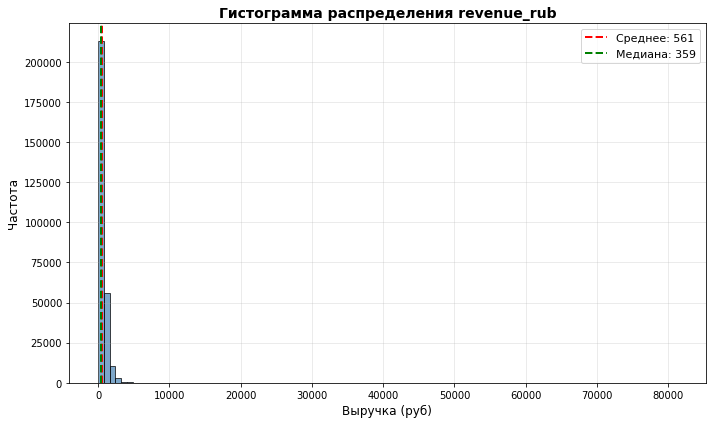

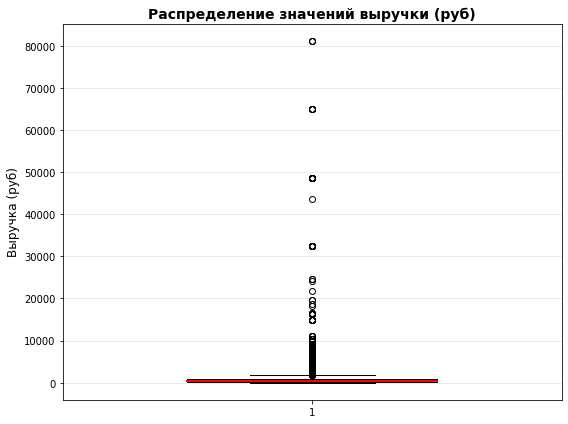

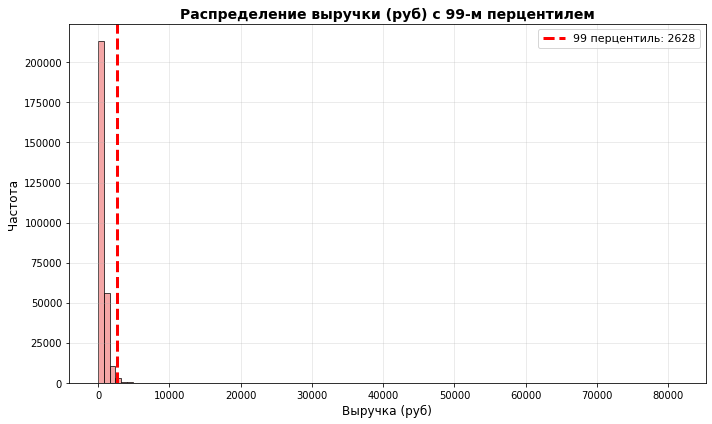


Размер датафрейма ДО фильтрации: 283829 строк
99-й перцентиль revenue_rub: 2628.42 руб
Строк с выбросами (> 99%): 2758 (0.97%)

Размер датафрейма ДО фильтрации: 283829 строк
Размер датафрейма ПОСЛЕ фильтрации: 281071 строк
Удалено строк: 2758

Новая статистика столбца revenue_rub:
count    281071.000000
mean        523.226811
std         512.697937
min           0.000000
25%         115.635000
50%         352.370000
75%         790.020000
max        2628.421739
Name: revenue_rub, dtype: float64
Среднее: 523.23
Медиана: 352.37
Максимум: 2628.42


In [11]:
# Рассмотрим столбец revenue_rub
print('Описательная статистика столбца revenue_rub:')
display(df2['revenue_rub'].describe())

# Рассмотрим по отдельности каждый показатель
print(f"\nМедиана: {df2['revenue_rub'].median():.2f}")
print(f"Мода: {df2['revenue_rub'].mode()}")
print(f"Среднее: {df2['revenue_rub'].mean():.2f}")
print(f"Стандартное отклонение: {df2['revenue_rub'].std():.2f}")
print(f"Количество пропусков: {df2['revenue_rub'].isna().sum()}")

# Рассчитаем IQR - показатель разбросов между 1-м и 3-м квантилями
print('\nМежквантильный размах - IQR:\n')
q1 = df2['revenue_rub'].quantile(0.25)
q3 = df2['revenue_rub'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers_low = (df2['revenue_rub'] < lower_bound).sum()
outliers_high = (df2['revenue_rub'] > upper_bound).sum()
outliers_total = outliers_low + outliers_high

print(f"Q1, первый квантиль (25%): {q1:.2f}")
print(f"Q3, третий квантиль (75%): {q3:.2f}")
print(f"IQR (межквантильный разброс): {iqr:.2f}")
print(f"Нижняя граница (Q1 - 1.5*IQR): {lower_bound:.2f}")
print(f"Верхняя граница (Q3 + 1.5*IQR): {upper_bound:.2f}")
print(f"Выбросов снизу: {outliers_low} ({outliers_low/len(df2)*100:.2f}%)")
print(f"Выбросов сверху: {outliers_high} ({outliers_high/len(df2)*100:.2f}%)")
print(f"Всего выбросов: {outliers_total} ({outliers_total/len(df2)*100:.2f}%)")

# Анализ выбросов по 99 перцентилю
percentile_99 = df2['revenue_rub'].quantile(0.99)
outliers_99 = (df2['revenue_rub'] > percentile_99).sum()
print(f"\nЗначений выше 99-го перцентиля: {outliers_99}")

# Визуализация revenue_rub

# График 1: Гистограмма с ср. значением и медианой
plt.figure(figsize=(10, 6))
plt.hist(df2['revenue_rub'], bins=100, edgecolor='black', alpha=0.7, color='steelblue')
plt.axvline(df2['revenue_rub'].mean(), color='red', linestyle='--', linewidth=2, label=f'Среднее: {df2["revenue_rub"].mean():.0f}')
plt.axvline(df2['revenue_rub'].median(), color='green', linestyle='--', linewidth=2, label=f'Медиана: {df2["revenue_rub"].median():.0f}')
plt.title('Гистограмма распределения revenue_rub', fontsize=14, fontweight='bold')
plt.xlabel('Выручка (руб)', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# График 2: Boxplot(ящик с усами)
plt.figure(figsize=(8, 6))
bp = plt.boxplot(df2['revenue_rub'], vert=True, patch_artist=True, widths=0.5)
bp['boxes'][0].set_facecolor('lightblue')
bp['medians'][0].set_color('red')
bp['medians'][0].set_linewidth(2)
plt.title('Распределение значений выручки (руб)', fontsize=14, fontweight='bold')
plt.ylabel('Выручка (руб)', fontsize=12)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# График 3: Гистограмма с отметкой 99-го перцентиля
plt.figure(figsize=(10, 6))
plt.hist(df2['revenue_rub'], bins=100, edgecolor='black', alpha=0.7, color='lightcoral')
plt.axvline(percentile_99, color='red', linestyle='--', linewidth=3, label=f'99 перцентиль: {percentile_99:.0f}')
plt.title('Распределение выручки (руб) с 99-м перцентилем', fontsize=14, fontweight='bold')
plt.xlabel('Выручка (руб)', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nРазмер датафрейма ДО фильтрации: {len(df2)} строк")
print(f"99-й перцентиль revenue_rub: {percentile_99:.2f} руб")
print(f"Строк с выбросами (> 99%): {outliers_99} ({outliers_99/len(df2)*100:.2f}%)")

# Фильтрация данных по 99 прецентилю
df3 = df2[df2['revenue_rub'] <= percentile_99].copy()

print(f"\nРазмер датафрейма ДО фильтрации: {len(df2)} строк")
print(f"Размер датафрейма ПОСЛЕ фильтрации: {len(df3)} строк")
print(f"Удалено строк: {outliers_99}")

print("\nНовая статистика столбца revenue_rub:")
print(df3['revenue_rub'].describe())
print(f"Среднее: {df3['revenue_rub'].mean():.2f}")
print(f"Медиана: {df3['revenue_rub'].median():.2f}")
print(f"Максимум: {df3['revenue_rub'].max():.2f}")

Результаты анализа распределения `revenue_rub`:
- после удаления отрицательных значений минимум равен 0, максимум 81 174.54: размах очень большой, присутствует выраженный правый хвост;
- среднее 560.87, медиана 358.53, мода 0: распределение асимметрично и не подчиняется нормальному закону;
- по правилу IQR верхняя граница выбросов равна 1 841.91, выбросов сверху 10 152 (3.58%), выбросов снизу нет.

Выполнена фильтрация по 99-му перцентилю (2 628.42 руб.): удалено 2 758 строк (0.97%). Статистика после фильтрации:
- среднее 523.23 (ранее 560.87);
- медиана 352.37 (ранее 358.53);
- максимум 2 628.42 (ранее 81 174.54).

Далее проанализируем столбец `tickets_count`, отражающий количество билетов в заказе.

Описательная статистика столбца tickets_count:


count    281071.000000
mean          2.741336
std           1.164954
min           1.000000
25%           2.000000
50%           3.000000
75%           3.000000
max          57.000000
Name: tickets_count, dtype: float64


Медиана: 3.00
Мода: 3
Среднее: 2.74
Стандартное отклонение: 1.17
Пропусков: 0
Минимум: 1
Максимум: 57

Распределение значений (топ 20)
  1 билетов:  40941 заказов (14.42%)
  2 билетов:  81679 заказов (28.78%)
  3 билетов:  89951 заказов (31.69%)
  4 билетов:  53655 заказов (18.90%)
  5 билетов:  13211 заказов ( 4.65%)
  6 билетов:   4206 заказов ( 1.48%)
  7 билетов:     62 заказов ( 0.02%)
  8 билетов:     21 заказов ( 0.01%)
  9 билетов:     36 заказов ( 0.01%)
 10 билетов:     19 заказов ( 0.01%)
 11 билетов:     13 заказов ( 0.00%)
 12 билетов:      4 заказов ( 0.00%)
 13 билетов:      7 заказов ( 0.00%)
 14 билетов:      4 заказов ( 0.00%)
 15 билетов:      2 заказов ( 0.00%)
 17 билетов:      6 заказов ( 0.00%)
 19 билетов:      5 заказов ( 0.00%)
 27 билетов:      2 заказов ( 0.00%)
 30 билетов:      2 заказов ( 0.00%)
 37 билетов:      1 заказов ( 0.00%)

Q1 1-й квантиль (25%): 2.00
Q3 3-й кванитль (75%): 3.00
IQR: 1.00
Нижняя граница (Q1 - 1.5*IQR): 0.50
Верхняя граница (Q3 +

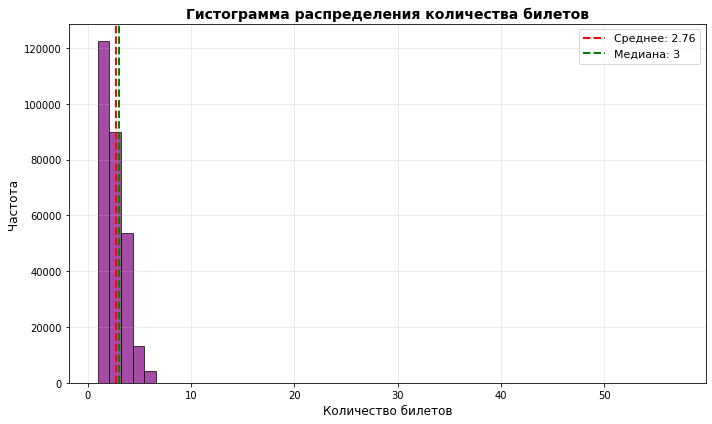

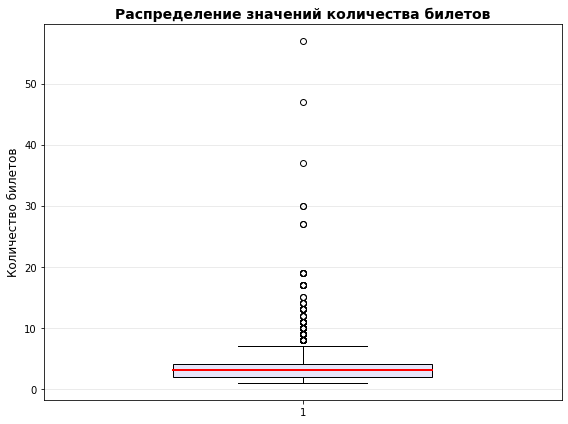

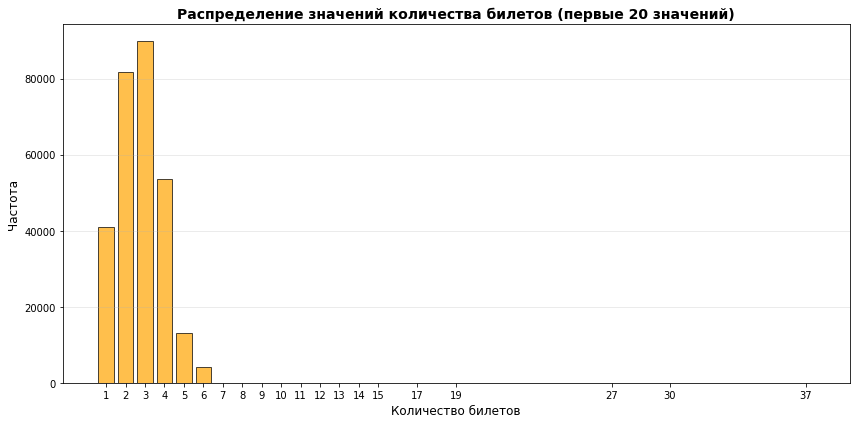

In [12]:
# Анализ столбца tickets_count
print('Описательная статистика столбца tickets_count:')
display(df3['tickets_count'].describe())
print(f"\nМедиана: {df3['tickets_count'].median():.2f}")
print(f"Мода: {df3['tickets_count'].mode().values[0]}")
print(f"Среднее: {df3['tickets_count'].mean():.2f}")
print(f"Стандартное отклонение: {df2['tickets_count'].std():.2f}")
print(f"Пропусков: {df3['tickets_count'].isnull().sum()}")
print(f"Минимум: {df3['tickets_count'].min()}")
print(f"Максимум: {df3['tickets_count'].max()}")

print("\nРаспределение значений (топ 20)")
value_counts = df2['tickets_count'].value_counts().sort_index().head(20)
for val, count in value_counts.items():
    pct = count / len(df2) * 100
    print(f"{val:>3} билетов: {count:>6} заказов ({pct:>5.2f}%)")

# Анализ выбросов IQR
q1 = df3['tickets_count'].quantile(0.25)
q3 = df3['tickets_count'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - iqr*1.5
upper_bound = q3 + iqr*1.5

outliers_low = (df3['tickets_count']<lower_bound).sum()
outliers_high = (df3['tickets_count']>upper_bound).sum()
outliers_total = outliers_low + outliers_high

print(f"\nQ1 1-й квантиль (25%): {q1:.2f}")
print(f"Q3 3-й кванитль (75%): {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Нижняя граница (Q1 - 1.5*IQR): {lower_bound:.2f}")
print(f"Верхняя граница (Q3 + 1.5*IQR): {upper_bound:.2f}")
print(f"Выбросов снизу: {outliers_low} ({outliers_low/len(df2)*100:.2f}%)")
print(f"Выбросов сверху: {outliers_high} ({outliers_high/len(df2)*100:.2f}%)")
print(f"Всего выбросов: {outliers_total} ({outliers_total/len(df2)*100:.2f}%)")

# График 1: Гистограмма с средним значением и медианой
plt.figure(figsize=(10, 6))
plt.hist(df2['tickets_count'], bins=50, edgecolor='black', alpha=0.7, color='purple')
plt.axvline(df2['tickets_count'].mean(), color='red', linestyle='--', linewidth=2, label=f'Среднее: {df2["tickets_count"].mean():.2f}')
plt.axvline(df2['tickets_count'].median(), color='green', linestyle='--', linewidth=2, label=f'Медиана: {df2["tickets_count"].median():.0f}')
plt.title('Гистограмма распределения количества билетов', fontsize=14, fontweight='bold')
plt.xlabel('Количество билетов', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# График 2: Boxplot
plt.figure(figsize=(8, 6))
bp = plt.boxplot(df2['tickets_count'], vert=True, patch_artist=True, widths=0.5)
bp['boxes'][0].set_facecolor('lavender')
bp['medians'][0].set_color('red')
bp['medians'][0].set_linewidth(2)
plt.title('Распределение значений количества билетов', fontsize=14, fontweight='bold')
plt.ylabel('Количество билетов', fontsize=12)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# График 3: Bar chart для значений (топ-20)
plt.figure(figsize=(12, 6))
tickets_dist = df2['tickets_count'].value_counts().sort_index().head(20)
plt.bar(tickets_dist.index, tickets_dist.values, edgecolor='black', alpha=0.7, color='orange')
plt.title('Распределение значений количества билетов (первые 20 значений)', fontsize=14, fontweight='bold')
plt.xlabel('Количество билетов', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.grid(True, alpha=0.3, axis='y')
plt.xticks(tickets_dist.index)
plt.tight_layout()
plt.show()

Результаты анализа `tickets_count` (после фильтрации по выручке):
- медиана и мода равны 3, среднее 2.74, максимум 57 (единичные заказы с большим числом билетов);
- распределение имеет правый хвост и не подчиняется нормальному закону: 1 билет в 14.42% заказов, 2 билета в 28.78%, 3 билета в 31.69%, 4 билета в 18.90%;
- пропусков в данных нет;
- по правилу IQR (верхняя граница 4.5 билета) выбросов 16 655 (5.87%), все они расположены выше Q3.

### 2.3 Промежуточный вывод

В качестве результата предобработки исходных данных получили новый датафрейм 'df3', в который добавили новый столбец 'revenue_rub', отражающий выручку за заказ в рублях, независимо от региона покупки.
Изучили данные на пропуски и дубликаты, удалили технические дубликаты и записи с отрицательной выручкой: пропуски, ожидаемо, оказались в поле 'days_since_prev' - это показатель того, что пользователь совершил не более 1-й покупки.
Был проведён детальный анализ, сопровождающийся графиками, числовых столбцов 'revenue_rub', 'tickets_count'.
Результат работы со столбцом 'revenue_rub':

- Отфильтрован по 99 перцентилю из-за большого количества выбросов;
- Не подчиняется нормальному закону.

Результат работы со столбцом 'tickets_count':
- Есть правый хвост;
- Не подчиняется нормальному закону.

Данные предобработаны и готовы к основной части работы!

## 3. Создание профиля пользователя
### 3.1 Построение профиля для каждого пользователя

Целью данного раздела является создание профиля пользователя по следующим метрикам:
- дата первого и последнего заказа;
- устройство, с которого был сделан первый заказ;
- регион, в котором был сделан первый заказ;
- билетный партнёр, к которому обращались при первом заказе;
- жанр первого посещённого мероприятия (поле event_type_main);
- общее количество заказов;
- средняя выручка с одного заказа в рублях;
- среднее количество билетов в заказе;
- среднее время между заказами.

Также добавим в данный профиль два новых столбца:
- is_two: совершил ли пользователь 2 и более заказа;
- is_five: совершил ли пользователь 5 и более заказов.

In [13]:
# Зададим новый датафрейм df4 с отсортированными значениями по id пользователя, дате заказа, id заказа
df3_sorted = df3.sort_values(['user_id', 'order_ts', 'order_id']).copy()

# Проверим корректность нового датафрейма
#display(df3_sorted.head(3))

# Изучаем первый заказ пользователя
first_order = (df3_sorted.drop_duplicates('user_id', keep='first')[['user_id',
                                                                   'order_dt',
                                                                   'order_ts',
                                                                   'device_type_canonical',
                                                                   'region_name',
                                                                   'service_name',
                                                                   'event_type_main']])
# Переименуем столбцы для удобства
first_order = first_order.rename(columns={'order_dt': 'first_order_dt', 'order_ts': 'first_order_ts'})

# Информация о первых заказах пользователей
print('Таблица с первыми заказами пользователей:')
display(first_order.head())

# Изучаем последний заказ пользователя
last_order = (df3_sorted.drop_duplicates('user_id', keep='last')[['user_id',
                                                                   'order_dt',
                                                                   'order_ts']])

# Переименуем столбцы для удобства
last_order = last_order.rename(columns={'order_dt': 'last_order_dt', 'order_ts': 'last_order_ts'})

# Информация о последних заказах пользователей
print('\nТаблица с последними заказами пользователей:')
display(last_order.head())

# Собираем агреггированную информацию о пользователях: кол-во заказов, средняя выручка с одного заказа (руб),
# среднее кол-во билетов в заказе, среднее время между заказами
profile_agg = (df3_sorted.groupby('user_id', as_index=False).agg(orders_cnt=('order_id', 'nunique'),
                                                                 avg_revenue_rub=('revenue_rub', 'mean'),
                                                                 avg_tickets=('tickets_count', 'mean'),
                                                                 avg_days_btwn=('days_since_prev', 'mean')))

# Выводим получившиеся агреггированные данные
print('\nАггрегированные данные по каждому пользователю')
display(profile_agg.head(3))

# Собираем общий профиль пользователя
user_profile = (profile_agg.merge(first_order, on='user_id', how='left').merge(last_order, on='user_id', how='left'))

# Выведем первые пять строк получившегося профиля пользователя
print('\nОбщий профиль пользователя:')
display(user_profile.head())

# Добавим новые бинарные признаки is_two и is_five
user_profile['is_two'] = (user_profile['orders_cnt'] >= 2).astype('int8')
user_profile['is_five'] = (user_profile['orders_cnt'] >= 5).astype('int8')

# Изменин порядок столбцов для удобства
user_profile = user_profile[['user_id', 'device_type_canonical', 'region_name', 'service_name', 'event_type_main', 'first_order_dt', 'first_order_ts', 'last_order_dt', 'last_order_ts',
                            'orders_cnt', 'avg_revenue_rub', 'avg_tickets', 'avg_days_btwn', 'is_two', 'is_five']]

# Получившийся датасет
print('\nПолный датасет с профилями пользователей:')
display(user_profile.head())

print('\nИнформация о полученном датасете:')
display(user_profile.info())

Таблица с первыми заказами пользователей:


,user_id,first_order_dt,first_order_ts,device_type_canonical,region_name,service_name,event_type_main
0,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,mobile,Каменевский регион,Край билетов,театр
1,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,mobile,Каменевский регион,Мой билет,выставки
3,000898990054619,2024-07-13,2024-07-13 19:40:48,mobile,Североярская область,Лови билет!,другое
6,00096d1f542ab2b,2024-08-15,2024-08-15 16:48:48,desktop,Каменевский регион,Край билетов,театр
7,000a55a418c128c,2024-09-29,2024-09-29 19:39:12,mobile,Поленовский край,Лучшие билеты,театр



Таблица с последними заказами пользователей:


,user_id,last_order_dt,last_order_ts
0,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03
2,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02
5,000898990054619,2024-10-23,2024-10-23 15:12:00
6,00096d1f542ab2b,2024-08-15,2024-08-15 16:48:48
8,000a55a418c128c,2024-10-15,2024-10-15 10:29:04



Аггрегированные данные по каждому пользователю


...

,user_id,orders_cnt,avg_revenue_rub,avg_tickets,avg_days_btwn,first_order_dt,first_order_ts,device_type_canonical,region_name,service_name,event_type_main,last_order_dt,last_order_ts
0,0002849b70a3ce2,1,1521.940000,4.000000,NaN,2024-08-20,2024-08-20 16:08:03,mobile,Каменевский регион,Край билетов,театр,2024-08-20,2024-08-20 16:08:03
1,0005ca5e93f2cf4,2,774.010000,3.000000,75.0,2024-07-23,2024-07-23 18:36:24,mobile,Каменевский регион,Мой билет,выставки,2024-10-06,2024-10-06 13:56:02
2,000898990054619,3,767.213333,2.666667,51.0,2024-07-13,2024-07-13 19:40:48,mobile,Североярская область,Лови билет!,другое,2024-10-23,2024-10-23 15:12:00
3,00096d1f542ab2b,1,917.830000,4.000000,NaN,2024-08-15,2024-08-15 16:48:48,desktop,Каменевский регион,Край билетов,театр,2024-08-15,2024-08-15 16:48:48
4,000a55a418c128c,2,61.310000,1.500000,16.0,2024-09-29,2024-09-29 19:39:12,mobile,Поленовский край,Лучшие билеты,театр,2024-10-15,2024-10-15 10:29:04



Полный датасет с профилями пользователей:


,user_id,device_type_canonical,region_name,service_name,event_type_main,first_order_dt,first_order_ts,last_order_dt,last_order_ts,orders_cnt,avg_revenue_rub,avg_tickets,avg_days_btwn,is_two,is_five
0,0002849b70a3ce2,mobile,Каменевский регион,Край билетов,театр,2024-08-20,2024-08-20 16:08:03,2024-08-20,2024-08-20 16:08:03,1,1521.940000,4.000000,NaN,0,0
1,0005ca5e93f2cf4,mobile,Каменевский регион,Мой билет,выставки,2024-07-23,2024-07-23 18:36:24,2024-10-06,2024-10-06 13:56:02,2,774.010000,3.000000,75.0,1,0
2,000898990054619,mobile,Североярская область,Лови билет!,другое,2024-07-13,2024-07-13 19:40:48,2024-10-23,2024-10-23 15:12:00,3,767.213333,2.666667,51.0,1,0
3,00096d1f542ab2b,desktop,Каменевский регион,Край билетов,театр,2024-08-15,2024-08-15 16:48:48,2024-08-15,2024-08-15 16:48:48,1,917.830000,4.000000,NaN,0,0
4,000a55a418c128c,mobile,Поленовский край,Лучшие билеты,театр,2024-09-29,2024-09-29 19:39:12,2024-10-15,2024-10-15 10:29:04,2,61.310000,1.500000,16.0,1,0



Информация о полученном датасете:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 21828 entries, 0 to 21827
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   user_id                21828 non-null  object        
 1   device_type_canonical  21828 non-null  object        
 2   region_name            21828 non-null  object        
 3   service_name           21828 non-null  object        
 4   event_type_main        21828 non-null  object        
 5   first_order_dt         21828 non-null  datetime64[ns]
 6   first_order_ts         21828 non-null  datetime64[ns]
 7   last_order_dt          21828 non-null  datetime64[ns]
 8   last_order_ts          21828 non-null  datetime64[ns]
 9   orders_cnt             21828 non-null  int64         
 10  avg_revenue_rub        21828 non-null  float64       
 11  avg_tickets            21828 non-null  float64       
 12  avg_days_btwn          13

None

Собрали профили пользователей в датафрейм 'user_profile', далее проверим его на наличие аномальных и неккоректных значений для дальнейшего исследовательского анализа.

### 3.2 Предобработка показателей профиля пользователя

Перед проведением исследовательского анализа обработаем полученные профили пользователей по следующим критериям:
- общее число пользователей в выборке;
- средняя выручка с одного заказа;
- доля пользователей, совершивших 2 и более заказа;
- доля пользователей, совершивших 5 и более заказов.

Также изучим статистические показатели:
- по общему числу заказов;
- по среднему числу билетов в заказе;
- по среднему количеству дней между покупками.

По результатам оценим данные: достаточно ли их по объёму, есть ли аномальные значения в данных о количестве заказов и среднем количестве билетов.

In [14]:
# Общее число пользователей в выборке
total_users = len(user_profile)
print(f"Общее число пользователей в выборке: {total_users}\n")

# Средняя выручка с одного заказа
total_revenue = (user_profile['avg_revenue_rub'] * user_profile['orders_cnt']).sum()
total_orders = user_profile['orders_cnt'].sum()
avg_revenue_per_order = round(total_revenue / total_orders, 2) # Округляем до второго знака
print(f"Средняя выручка с одного заказа: {avg_revenue_per_order}\n")

# Доля пользователей, совершивших 2 и более заказа
share_two_or_more = round(user_profile['is_two'].mean(), 4)
print(f"Доля пользователей, совершивших 2 и более заказа: {share_two_or_more}, {share_two_or_more * 100}%")

# Доля пользователей, совершивших 5 и более заказов
share_five_or_more = round(user_profile['is_five'].mean(), 4)
print(f"Доля пользователей, совершивших 5 и более заказов: {share_five_or_more}, {share_five_or_more * 100}%")

Общее число пользователей в выборке: 21828

Средняя выручка с одного заказа: 523.23

Доля пользователей, совершивших 2 и более заказа: 0.6157, 61.57%
Доля пользователей, совершивших 5 и более заказов: 0.2877, 28.77%


В выборке 21 828 пользователей, средняя выручка с одного заказа составляет 523.23 рубля. 61.57% пользователей совершили два и более заказа, 28.77% совершили пять и более заказов, что говорит о высокой доле лояльных клиентов.

Далее рассмотрим статистические показатели следующих полей:
- общее число заказов;
- среднее число билетов в заказе;
- среднее количество дней между заказами.

Статистические показатели общего числа заказов (orders_cnt):


count    21828.000000
mean        12.876626
std        119.003953
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max       9986.000000
Name: orders_cnt, dtype: float64

Мода: 1
Размах: 9985


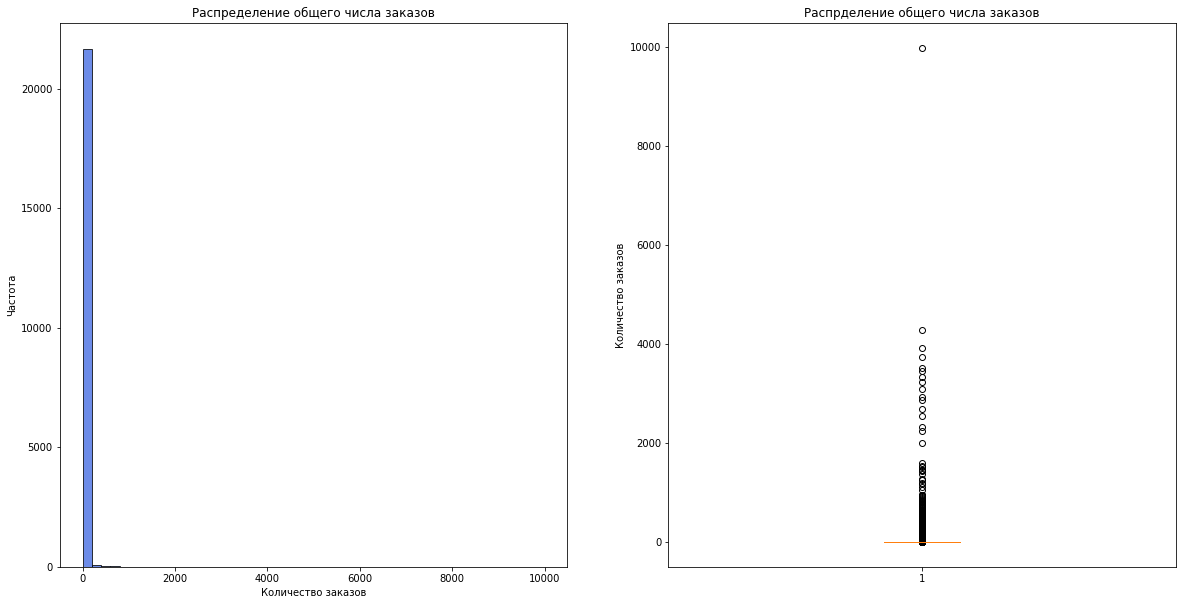

90%-й перцентиль orders_cnt: 15.0
95%-й перцентиль orders_cnt: 31.0
99%-й перцентиль orders_cnt: 146.0
99.9%-й перцентиль orders_cnt: 1443.2110000000175
----------------------------------------------------------------------------------------------------

Статистические показатели среднего числа билетов в заказе:


count    21828.000000
mean         2.744584
std          0.912690
min          1.000000
25%          2.000000
50%          2.750000
75%          3.076923
max         11.000000
Name: avg_tickets, dtype: float64

Мода: 3.0
Размах: 10.0
90%-й перцентиль orders_cnt: 4.0
95%-й перцентиль orders_cnt: 4.0
99%-й перцентиль orders_cnt: 5.0
99.9%-й перцентиль orders_cnt: 6.0
----------------------------------------------------------------------------------------------------

Статистические показатели среднего количества дней между заказами:


count    13469.000000
mean        16.014607
std         22.458421
min          0.000000
25%          1.000000
50%          8.200000
75%         20.666667
max        148.000000
Name: avg_days_btwn, dtype: float64

Мода: 0.0
Размах: 148.0
90%-й перцентиль orders_cnt: 41.733333333333576
95%-й перцентиль orders_cnt: 62.0
99%-й перцентиль orders_cnt: 114.0
99.9%-й перцентиль orders_cnt: 142.0


In [15]:
# Рассчёт метрик для orders_cnt
print('Статистические показатели общего числа заказов (orders_cnt):')
display(user_profile['orders_cnt'].describe())
print(f"Мода: {user_profile['orders_cnt'].mode()[0]}")
print(f"Размах: {user_profile['orders_cnt'].max() - user_profile['orders_cnt'].min()}")

# Визуализация распределения данных orders_cnt
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
axes[0].hist(user_profile['orders_cnt'], bins=50, edgecolor='black', color='RoyalBlue', alpha=0.77)
axes[0].set_xlabel('Количество заказов')
axes[0].set_ylabel('Частота')
axes[0].set_title('Распределение общего числа заказов')
axes[1].boxplot(user_profile['orders_cnt'])
axes[1].set_ylabel('Количество заказов')
axes[1].set_title('Распрделение общего числа заказов')
plt.show()

# Расчёт перцентилей для поля orders_cnt
for p in [90, 95, 99, 99.9]:
    print(f"{p}%-й перцентиль orders_cnt: {user_profile['orders_cnt'].quantile(p/100)}")

print('-'*100)

# Расчёт метрик для avg_tickets
print('\nСтатистические показатели среднего числа билетов в заказе:')
display(user_profile['avg_tickets'].describe())
print(f"Мода: {user_profile['avg_tickets'].mode()[0]}")
print(f"Размах: {user_profile['avg_tickets'].max() - user_profile['avg_tickets'].min()}")

# Расчёт перцентилей для поля avg_tickets
for p in [90, 95, 99, 99.9]:
    print(f"{p}%-й перцентиль orders_cnt: {user_profile['avg_tickets'].quantile(p/100)}")

print('-'*100)


# Расчёт метрик для avg_days_btwn
print('\nСтатистические показатели среднего количества дней между заказами:')
display(user_profile['avg_days_btwn'].describe())
print(f"Мода: {user_profile['avg_days_btwn'].mode()[0]}")
print(f"Размах: {user_profile['avg_days_btwn'].max() - user_profile['avg_days_btwn'].min()}")

# Расчёт перцентилей для поля avg_days_btwn
for p in [90, 95, 99, 99.9]:
    print(f"{p}%-й перцентиль orders_cnt: {user_profile['avg_days_btwn'].quantile(p/100)}")

По итогам анализа можно сделать вывод, что поле order_cnt имеет аномалии: послее 99 перцентиля данные сильно искажаются и появляются аномально большие значения, из-за чего распределение имеет большой правых хвост. Верным решением будет фильтрация по 99 перцентилю для проведения более точного исследовательского анализа, так как такие аномалии будут искажать общую картину поведения пользователей.

In [16]:
# Фильтрация по 99 перцентилю поля orders_cnt
q99_orders_cnt = user_profile['orders_cnt'].quantile(0.99)
print(f"Значение 99-го перцентиля общиего числа заказов: {q99_orders_cnt}")

# Создаем новый отфильтрованный датафрейм user_profile_filtered
user_profile_filtered = user_profile[user_profile['orders_cnt'] <= q99_orders_cnt].copy()

# Выводим информацию об изменениях в датафрейме
removed_count = len(user_profile) - len(user_profile_filtered)
print(f"Удалено записей: {removed_count}")
print(f"Осталось записей: {len(user_profile_filtered)}")
print(f"Доля удалённых записей: {removed_count / len(user_profile):.2%}")

Значение 99-го перцентиля общиего числа заказов: 146.0
Удалено записей: 218
Осталось записей: 21610
Доля удалённых записей: 1.00%


Статистические показатели общего числа заказов (orders_cnt):


count    21610.000000
mean         6.350023
std         13.773433
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max        146.000000
Name: orders_cnt, dtype: float64

Мода: 1
Размах: 145


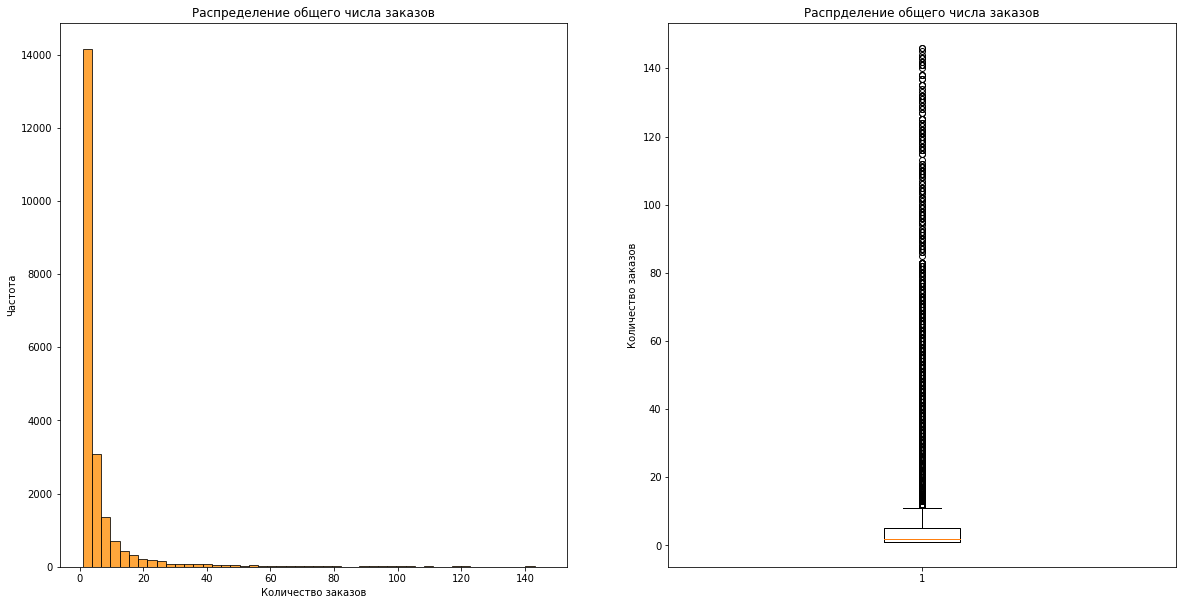

90%-й перцентиль orders_cnt: 13.0
95%-й перцентиль orders_cnt: 26.0
99%-й перцентиль orders_cnt: 77.0
99.9%-й перцентиль orders_cnt: 134.39100000000326
----------------------------------------------------------------------------------------------------

Статистические показатели среднего числа билетов в заказе:


count    21610.000000
mean         2.744808
std          0.917149
min          1.000000
25%          2.000000
50%          2.750000
75%          3.100000
max         11.000000
Name: avg_tickets, dtype: float64

Мода: 3.0
Размах: 10.0
90%-й перцентиль orders_cnt: 4.0
95%-й перцентиль orders_cnt: 4.0
99%-й перцентиль orders_cnt: 5.0
99.9%-й перцентиль orders_cnt: 6.0
----------------------------------------------------------------------------------------------------

Статистические показатели среднего количества дней между заказами:


count    13251.000000
mean        16.270197
std         22.553078
min          0.000000
25%          1.430632
50%          8.500000
75%         21.000000
max        148.000000
Name: avg_days_btwn, dtype: float64

Мода: 0.0
Размах: 148.0
90%-й перцентиль orders_cnt: 42.0
95%-й перцентиль orders_cnt: 62.0
99%-й перцентиль orders_cnt: 114.0
99.9%-й перцентиль orders_cnt: 142.0


In [17]:
# Статистические показатели по новому датасету

# Рассчёт метрик для orders_cnt
print('Статистические показатели общего числа заказов (orders_cnt):')
display(user_profile_filtered['orders_cnt'].describe())
print(f"Мода: {user_profile_filtered['orders_cnt'].mode()[0]}")
print(f"Размах: {user_profile_filtered['orders_cnt'].max() - user_profile_filtered['orders_cnt'].min()}")

# Визуализация распределения данных orders_cnt
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
axes[0].hist(user_profile_filtered['orders_cnt'], bins=50, edgecolor='black', color='darkorange', alpha=0.77)
axes[0].set_xlabel('Количество заказов')
axes[0].set_ylabel('Частота')
axes[0].set_title('Распределение общего числа заказов')
axes[1].boxplot(user_profile_filtered['orders_cnt'])
axes[1].set_ylabel('Количество заказов')
axes[1].set_title('Распрделение общего числа заказов')
plt.show()

# Расчёт перцентилей для поля orders_cnt
for p in [90, 95, 99, 99.9]:
    print(f"{p}%-й перцентиль orders_cnt: {user_profile_filtered['orders_cnt'].quantile(p/100)}")

print('-'*100)

# Расчёт метрик для avg_tickets
print('\nСтатистические показатели среднего числа билетов в заказе:')
display(user_profile_filtered['avg_tickets'].describe())
print(f"Мода: {user_profile_filtered['avg_tickets'].mode()[0]}")
print(f"Размах: {user_profile_filtered['avg_tickets'].max() - user_profile_filtered['avg_tickets'].min()}")

# Расчёт перцентилей для поля avg_tickets
for p in [90, 95, 99, 99.9]:
    print(f"{p}%-й перцентиль orders_cnt: {user_profile_filtered['avg_tickets'].quantile(p/100)}")

print('-'*100)


# Расчёт метрик для avg_days_btwn
print('\nСтатистические показатели среднего количества дней между заказами:')
display(user_profile_filtered['avg_days_btwn'].describe())
print(f"Мода: {user_profile_filtered['avg_days_btwn'].mode()[0]}")
print(f"Размах: {user_profile_filtered['avg_days_btwn'].max() - user_profile_filtered['avg_days_btwn'].min()}")

# Расчёт перцентилей для поля avg_days_btwn
for p in [90, 95, 99, 99.9]:
    print(f"{p}%-й перцентиль orders_cnt: {user_profile_filtered['avg_days_btwn'].quantile(p/100)}")

### 3.3 Промежуточный вывод

В ходе данного раздела была проделана работа по созданию профиля пользователя, который отражает следующие характеристики для каждого покупателя сервиса:
- Уникальный идентефикатор;
- Регион первого заказа;
- Билетный сервис, через который был совершён первый заказ;
- Дата первого заказ;
- Дата последнего заказа;
- Количество заказов;
- Средняя выручка;
- Среднее количество билетов;
- Среднее количество дней между покупками.

После получения данных метрик был проведен анализ основных числовых показателей на аномальные и некорректные значения, анализ данных показал, что поле с количеством заказов содержит аномально большие значения, было принято решение отфильтровать данного поле по 99 перцентилю, дабы не искажать общую картину. Поля с средним количеством билетов и средним количеством дней между заказами содержат в полне реальные показатели, следовательно, их решили оставить оригинальными.
Следующим этапом проекта будет исследовательский анализ данных.

## 4. Исследовательский анализ данных
### 4.1 Исследование признаков первого заказа и их связи с возвращением на платформу
#### 4.1.1 Изучение распределения пользователей по признакам
На данном этапе изучи распределение пользователей по следующим признакам:
- по типу первого мероприятия;
- по типу устройства, с которого совершена первая покупка;
- по региону проведения первого мероприятия;
- по билетному оператору, продавшему билеты на первое мероприятие.

Нам необходимо ответить на следующий вопрос для понимания общей картины: равномерно ли распределены пользователи по сегментам или есть выраженные «точки входа» - сегменты с наибольшим числом пользователей?

Распределение по типу первого мероприятия:


,Количество,"Доля, %"
концерты,9563,44.3
другое,5394,25.0
театр,4240,19.6
стендап,1109,5.1
спорт,795,3.7
выставки,414,1.9
ёлки,95,0.4



Распределение по типу устройства:


,Количество,"Доля, %"
mobile,17895,82.8
desktop,3715,17.2


Лучшие 20 регионов по количеству пользователей


,Количество,"Доля, %"
Каменевский регион,7087,32.8
Североярская область,3761,17.4
Широковская область,1220,5.6
Озернинский край,675,3.1
Малиновоярский округ,526,2.4
Шанырский регион,502,2.3
Травяная область,488,2.3
Светополянский округ,457,2.1
Речиновская область,440,2.0
Яблоневская область,411,1.9



Всего уникальных регионов: 81


Лучшие 20 билетных операторов


,Количество,"Доля, %"
Билеты без проблем,5160,23.9
Мой билет,2970,13.7
Лови билет!,2813,13.0
Билеты в руки,2557,11.8
Облачко,2177,10.1
Весь в билетах,1286,6.0
Лучшие билеты,1179,5.5
Прачечная,581,2.7
Край билетов,454,2.1
Дом культуры,357,1.7



Всего уникальных операторов: 34


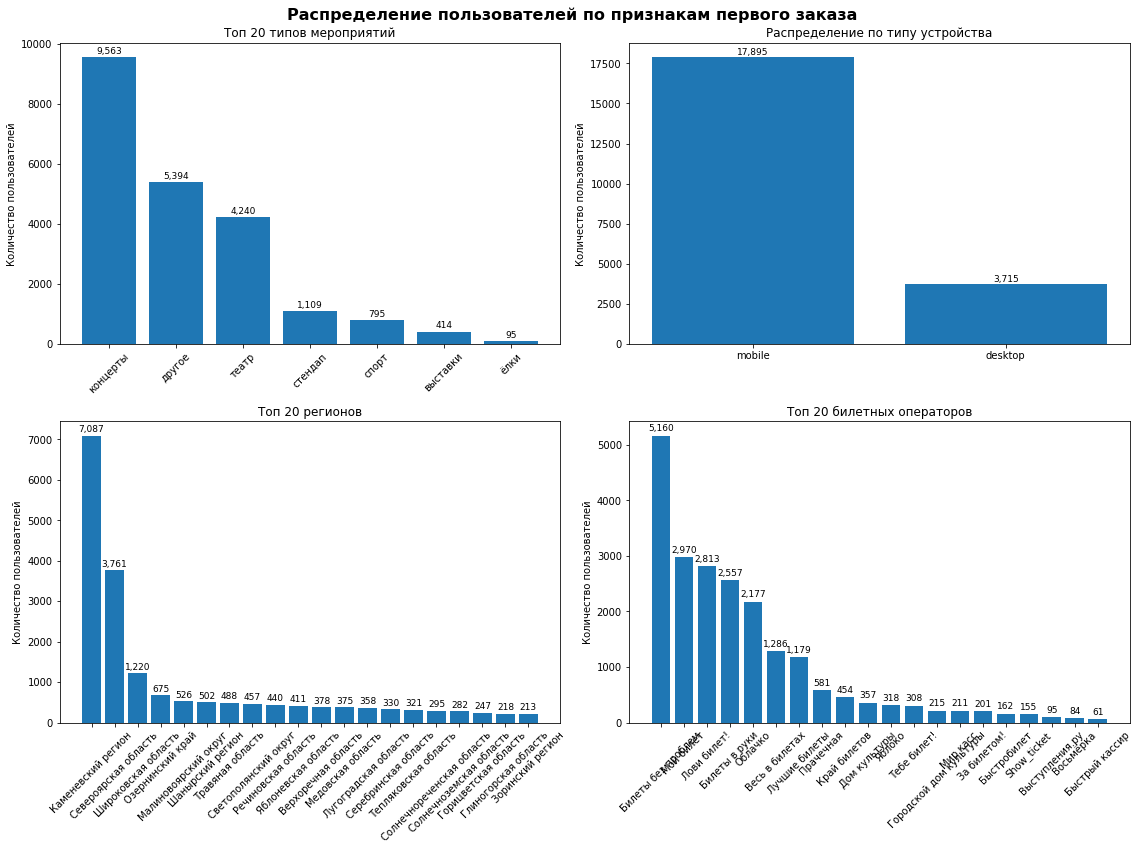

In [18]:
# Настроим параметры для графиков
# plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 8)

# 1) Распрделение по типу первого мероприятия
event_type_dist = user_profile_filtered['event_type_main'].value_counts()
event_type_pct = (event_type_dist / len(user_profile_filtered)*100).round(1)

print('Распределение по типу первого мероприятия:')
event_type_df = pd.DataFrame({'Количество': event_type_dist, 'Доля, %': event_type_pct})
display(event_type_df)

# 2) Распределение по типу устройства
device_dist = user_profile_filtered['device_type_canonical'].value_counts()
device_pct = (device_dist / len(user_profile_filtered)*100).round(1)

print('\nРаспределение по типу устройства:')
device_df = pd.DataFrame({'Количество': device_dist, 'Доля, %': device_pct})
display(device_df)

# 3) Распределение по региону
region_dist = user_profile_filtered['region_name'].value_counts()
region_pct = (region_dist / len(user_profile_filtered) * 100).round(1)

print("Лучшие 20 регионов по количеству пользователей")
region_df = pd.DataFrame({
    'Количество': region_dist.head(20),
    'Доля, %': region_pct.head(20)
})
display(region_df)
print(f"\nВсего уникальных регионов: {user_profile_filtered['region_name'].nunique()}")
print("\n")

# 4) Распределение по билетному оператору
service_dist = user_profile_filtered['service_name'].value_counts()
service_pct = (service_dist / len(user_profile_filtered) * 100).round(1)

print("Лучшие 20 билетных операторов")
service_df = pd.DataFrame({
    'Количество': service_dist.head(20),
    'Доля, %': service_pct.head(20)
})
display(service_df)
print(f"\nВсего уникальных операторов: {user_profile_filtered['service_name'].nunique()}")

# Визуализация полученных распределений
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Распределение пользователей по признакам первого заказа', fontsize=16, fontweight='bold')

# 1. Тип мероприятия
bars1 = axes[0, 0].bar(event_type_df.index[:10], event_type_df['Количество'][:10])
axes[0, 0].set_title('Топ 20 типов мероприятий')
axes[0, 0].set_ylabel('Количество пользователей')
axes[0, 0].tick_params(axis='x', rotation=45)
for bar in bars1:
    height = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2., height + 50,
                   f'{height:,}', ha='center', va='bottom', fontsize=9)

# 2. Тип устройства
bars2 = axes[0, 1].bar(device_df.index, device_df['Количество'])
axes[0, 1].set_title('Распределение по типу устройства')
axes[0, 1].set_ylabel('Количество пользователей')
for bar in bars2:
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2., height + 50,
                   f'{height:,}', ha='center', va='bottom', fontsize=9)

# 3. Регионы (ТОП-10)
bars3 = axes[1, 0].bar(region_df.index, region_df['Количество'])
axes[1, 0].set_title('Топ 20 регионов')
axes[1, 0].set_ylabel('Количество пользователей')
axes[1, 0].tick_params(axis='x', rotation=45)
for bar in bars3:
    height = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2., height + 50,
                   f'{height:,}', ha='center', va='bottom', fontsize=9)

# 4. Операторы (ТОП-10)
bars4 = axes[1, 1].bar(service_df.index, service_df['Количество'])
axes[1, 1].set_title('Топ 20 билетных операторов')
axes[1, 1].set_ylabel('Количество пользователей')
axes[1, 1].tick_params(axis='x', rotation=45)
for bar in bars4:
    height = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2., height + 50,
                   f'{height:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

По графикам отвечаем на вопрос: равномерно ли распределены пользователи по сегментам или есть выраженные «точки входа» - сегменты с наибольшим числом пользователей.

Выраженные точки входа есть: около 83% пользователей оформляют первый заказ с мобильных устройств; на концерты приходится примерно в 1.8 раза больше пользователей, чем на ближайший по численности тип «другое»; Каменевский регион и Североярская область существенно преобладают по числу пользователей; из 36 билетных операторов семь крупнейших обслуживают около 83% заказов.

#### 4.1.2 Анализ возвратов пользователей
На данном этапе нашей главной целью будет выявить какие сегменты пользователей чаще всего возвращаются на Яндекс Афишу, есть ли "точки входа", в которых пользователи чаще совершают повторный заказ.

Для понимания общей картины необходимо ответить на следующие вопросы:
- Какие сегменты пользователей чаще возвращаются на Яндекс Афишу?
- Наблюдаются ли успешные «точки входа» - такие сегменты, в которых пользователи чаще совершают повторный заказ, чем в среднем по выборке?

In [19]:
# Функция для анализа возвратов по сегменту
def analyze_retention_by_segment(df, segment_col, top_n=10):
    """
    Анализирует возвраты по сегменту
    """
    # Общая статистика по сегменту
    segment_stats = df.groupby(segment_col).agg(
        total_users=('user_id', 'count'),
        returning_users=('is_two', 'sum'),
        loyal_users=('is_five', 'sum')
    ).reset_index()

    # Расчет долей
    segment_stats['return_rate'] = (segment_stats['returning_users'] / segment_stats['total_users'] * 100).round(2)
    segment_stats['loyal_rate'] = (segment_stats['loyal_users'] / segment_stats['total_users'] * 100).round(2)

    # Средний по выборке
    avg_return_rate = (df['is_two'].mean() * 100).round(2)
    avg_loyal_rate = (df['is_five'].mean() * 100).round(2)

    # Сортируем по количеству пользователей
    segment_stats = segment_stats.sort_values('total_users', ascending=False)

    # Для визуализации берем топ-N по количеству пользователей
    if len(segment_stats) > top_n:
        segment_stats_top = segment_stats.head(top_n).copy()
    else:
        segment_stats_top = segment_stats.copy()

    return segment_stats, segment_stats_top, avg_return_rate, avg_loyal_rate

# Анализ по типу мероприятия
event_stats, event_stats_top, avg_return, avg_loyal = analyze_retention_by_segment(
    user_profile_filtered, 'event_type_main', top_n=10
)

print("Анализ возвращения пользователя по типу мероприятия")
print(f"Средняя доля возвращений по выборке (доля клиентов с 2+ заказами): {avg_return}%")
print(f"Средняя доля лояльных клиентов (5+ заказов): {avg_loyal}%")
print("\nСтатистика по сегментам:")
print(event_stats_top.to_string(index=False))
print("\n")

# Анализ по типу устройства
device_stats, device_stats_top, _, _ = analyze_retention_by_segment(
    user_profile_filtered, 'device_type_canonical', top_n=10
)

print("Анализ возвращения клиентов по типу устройства")
print(device_stats_top.to_string(index=False))
print("\n")

# Анализ по региону
region_stats, region_stats_top, _, _ = analyze_retention_by_segment(
    user_profile_filtered, 'region_name', top_n=10
)

print("Анализ возвращения клиентов по региону (топ 10 регионов)")
print(region_stats_top.to_string(index=False))
print("\n")

# Анализ по оператору
service_stats, service_stats_top, _, _ = analyze_retention_by_segment(
    user_profile_filtered, 'service_name', top_n=10
)

print("Анализ возвращения клиентов по оператору (топ 10 операторов)")
print(service_stats_top.to_string(index=False))

Анализ возвращения пользователя по типу мероприятия
Средняя доля возвращений по выборке (доля клиентов с 2+ заказами): 61.18%
Средняя доля лояльных клиентов (5+ заказов): 28.05%

Статистика по сегментам:
event_type_main  total_users  returning_users  loyal_users  return_rate  loyal_rate
       концерты         9563           5904.0       2691.0        61.74       28.14
         другое         5394           3201.0       1525.0        59.34       28.27
          театр         4240           2684.0       1244.0        63.30       29.34
        стендап         1109            673.0        295.0        60.69       26.60
          спорт          795            442.0        180.0        55.60       22.64
       выставки          414            265.0        109.0        64.01       26.33
           ёлки           95             53.0         17.0        55.79       17.89


Анализ возвращения клиентов по типу устройства
device_type_canonical  total_users  returning_users  loyal_users  return_ra

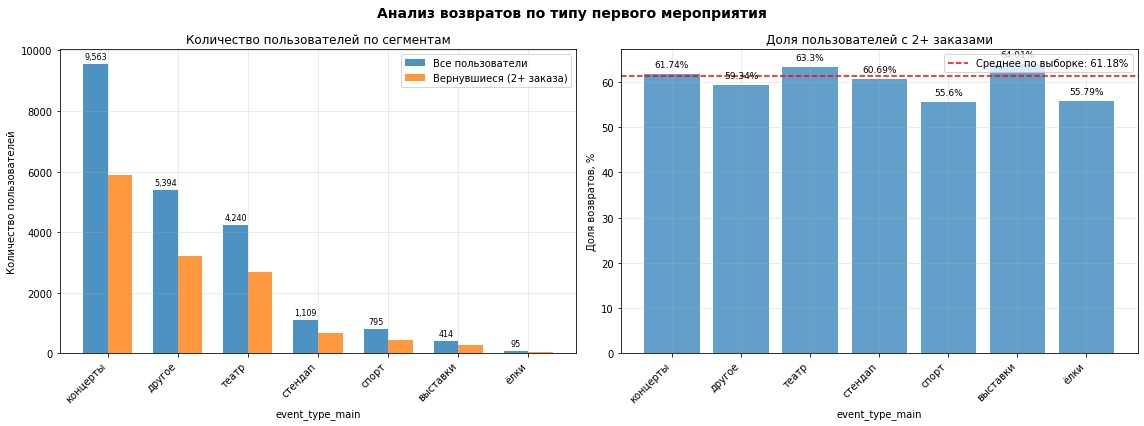

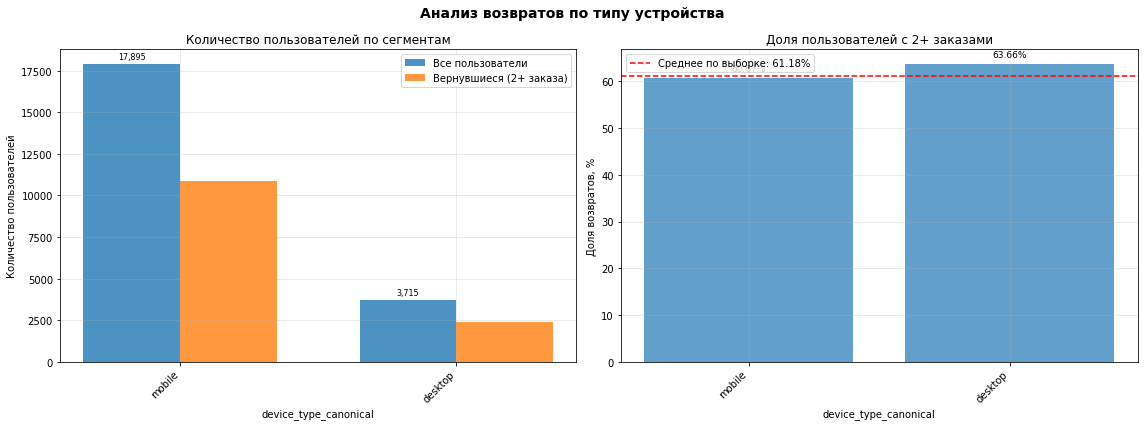

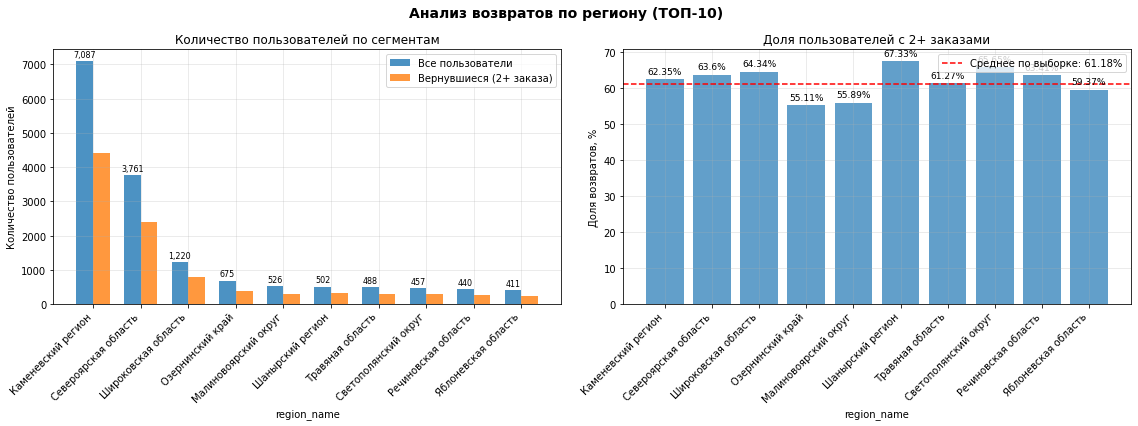

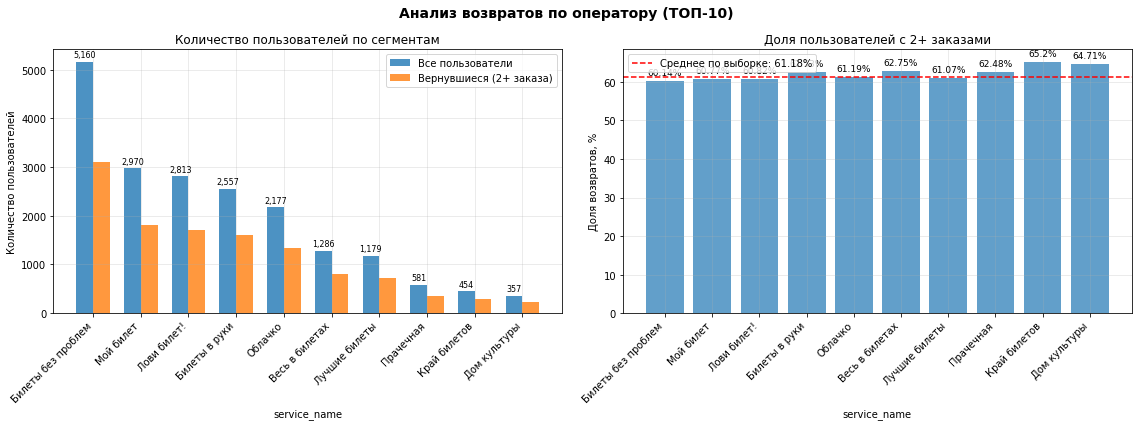

In [20]:
# Создаем функцию для построения графика
def plot_segment_retention(segment_stats_top, segment_col, avg_return_rate, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle(title, fontsize=14, fontweight='bold')

    # График 1: Количество пользователей и возвратов
    x = range(len(segment_stats_top))
    width = 0.35

    bars1 = ax1.bar([i - width/2 for i in x], segment_stats_top['total_users'],
                    width, label='Все пользователи', alpha=0.8)
    bars2 = ax1.bar([i + width/2 for i in x], segment_stats_top['returning_users'],
                    width, label='Вернувшиеся (2+ заказа)', alpha=0.8)

    ax1.set_xlabel(segment_col)
    ax1.set_ylabel('Количество пользователей')
    ax1.set_title('Количество пользователей по сегментам')
    ax1.set_xticks(x)
    ax1.set_xticklabels(segment_stats_top[segment_col], rotation=45, ha='right')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Добавляем подписи
    for bar in bars1:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + max(segment_stats_top['total_users'])*0.01,
                f'{int(height):,}', ha='center', va='bottom', fontsize=8)

    # График 2: Доля возвратов
    bars3 = ax2.bar(x, segment_stats_top['return_rate'], alpha=0.7)
    ax2.axhline(y=avg_return_rate, color='r', linestyle='--',
                label=f'Среднее по выборке: {avg_return_rate}%')

    ax2.set_xlabel(segment_col)
    ax2.set_ylabel('Доля возвратов, %')
    ax2.set_title('Доля пользователей с 2+ заказами')
    ax2.set_xticks(x)
    ax2.set_xticklabels(segment_stats_top[segment_col], rotation=45, ha='right')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # Добавляем подписи
    for bar in bars3:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 1,
                f'{height}%', ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.show()

# Визуализация для типов мероприятий
plot_segment_retention(event_stats_top, 'event_type_main', avg_return,
                      'Анализ возвратов по типу первого мероприятия')

# Визуализация для устройств
plot_segment_retention(device_stats_top, 'device_type_canonical', avg_return,
                      'Анализ возвратов по типу устройства')

# Визуализация для регионов
plot_segment_retention(region_stats_top, 'region_name', avg_return,
                      'Анализ возвратов по региону (ТОП-10)')

# Визуализация для операторов
plot_segment_retention(service_stats_top, 'service_name', avg_return,
                      'Анализ возвратов по оператору (ТОП-10)')

Для понимания общей картины отвечаем на вопросы:

- Какие сегменты пользователей чаще возвращаются на Яндекс Афишу?
- Есть ли успешные «точки входа», то есть сегменты с долей повторных заказов выше средней по выборке (около 61.2%)?

1) Тип первого мероприятия: выше среднего доля возвращений у пользователей, начавших с выставок (64.01%), театра (63.30%) и концертов (61.74%); ниже среднего у спорта (55.60%) и «ёлок» (55.79%). Выставки малочисленны (414 пользователей), поэтому оценка для них менее устойчива.
2) Тип устройства: с десктопа возвращаются чаще (63.66%), чем с мобильных устройств (60.67%), хотя абсолютное число вернувшихся больше среди мобильных пользователей, так как их значительно больше.
3) Регион: среди крупнейших регионов выше среднего доля возвратов в Широковской области (64.34%), Североярской области (63.60%) и Каменевском регионе (62.35%); ниже среднего в Озернинском крае (55.11%) и Малиновоярском округе (55.89%).
4) Оператор: среди крупнейших операторов наибольшая доля возвратов у «Края билетов» (65.20%) и «Дома культуры» (64.71%), у обоих небольшое число пользователей; крупнейший оператор «Билеты без проблем» (5 160 пользователей) имеет долю возвратов 60.14%, близкую к средней.

#### 4.1.3 Проверка продуктовых гипотез
- Гипотеза 1. Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.
- Гипотеза 2. В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.


- Ответ на первую гипотезу: гипотеза не подтвердилась. Доля вернувшихся пользователей среди начавших со спортивных мероприятий составляет 55.60%, среди начавших с концертов 61.74%.
- Ответ на вторую гипотезу: однозначно подтвердить нельзя. В 25 наиболее активных регионах (топ-30% по числу пользователей) доля повторных заказов равна 61.71%, в остальных 56 регионах 56.31%; разница 5.41 п.п. значима при объединении пользователей в группы (z-тест, p < 0.001). Однако корреляция между размером региона и долей возвратов слабая (r = 0.12), среди крупнейших регионов нет единой закономерности (отклонение от среднего от -6.07 до +3.16 п.п.), а доли в малых регионах сильно колеблются из-за небольшого числа пользователей. Z-тест по объединённым группам не учитывает различия между регионами внутри группы, поэтому результат следует считать слабым свидетельством, а не доказательством. Для строгой проверки требуется модель с учётом кластеризации пользователей по регионам.

Количество регионов в каждой группе:
Активные регионы (топ-30% по количеству пользователей): 25
Остальные регионы: 56
Порог для попадания в активные: 152 пользователей

Сравнение долей повторных заказов:
Активные регионы (топ-30%):
  - Количество пользователей: 19,493
  - Доля повторных заказов: 61.71%
  - Количество повторных покупателей: 12,030

Остальные регионы:
  - Количество пользователей: 2,117
  - Доля повторных заказов: 56.31%
  - Количество повторных покупателей: 1,192

Разница: 5.41% пунктов

Статистический тест значимости различий:
Z-статистика: 4.8497
p-value: 0.000001
✓ Различия СТАТИСТИЧЕСКИ ЗНАЧИМЫ (p < 0.05)
✓ В активных регионах доля повторных заказов ДЕЙСТВИТЕЛЬНО ВЫШЕ, чем в менее активных регионах

ДОПОЛНИТЕЛЬНЫЙ АНАЛИЗ


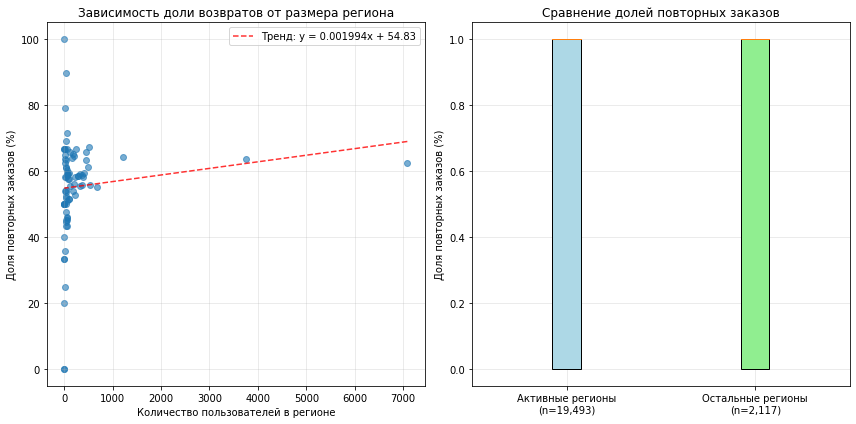


Корреляция Пирсона между размером региона и долей возвратов: 0.1206
Обнаружена очень слабая корреляция

АНАЛИЗ ТОП-5 САМЫХ АКТИВНЫХ РЕГИОНОВ:

Каменевский регион:
  - Пользователей: 7,087
  - Доля повторных заказов: 62.35%
  - Отклонение от средней (61.18%): +1.17%

Североярская область:
  - Пользователей: 3,761
  - Доля повторных заказов: 63.60%
  - Отклонение от средней (61.18%): +2.42%

Широковская область:
  - Пользователей: 1,220
  - Доля повторных заказов: 64.34%
  - Отклонение от средней (61.18%): +3.16%

Озернинский край:
  - Пользователей: 675
  - Доля повторных заказов: 55.11%
  - Отклонение от средней (61.18%): -6.07%

Малиновоярский округ:
  - Пользователей: 526
  - Доля повторных заказов: 55.89%
  - Отклонение от средней (61.18%): -5.29%

ДОПОЛНИТЕЛЬНАЯ ПРОВЕРКА С ПОМОЩЬЮ T-ТЕСТА:
t-статистика (Уэлча): 4.7731
p-value: 0.000002
T-тест также подтверждает статистическую значимость различий


In [22]:
# Проведем статистический тест для более обоснованного ответа на гипотезу номер 2

# Анализ зависимости доли повторных заказов от активности региона

# Рассчёт активности регионов
region_activity = user_profile_filtered.groupby('region_name').agg(
    total_users=('user_id', 'count'),
    returning_rate=('is_two', 'mean')
).reset_index()

# Сортируем по количеству пользователей
region_activity = region_activity.sort_values('total_users', ascending=False)

# Разделим регионы на 2 группы: активные (топ-30% по количеству пользователей) и остальные
threshold_30 = region_activity['total_users'].quantile(0.7)  # 70-й перцентиль
active_regions = region_activity[region_activity['total_users'] >= threshold_30]['region_name'].tolist()
other_regions = region_activity[region_activity['total_users'] < threshold_30]['region_name'].tolist()

print("Количество регионов в каждой группе:")
print(f"Активные регионы (топ-30% по количеству пользователей): {len(active_regions)}")
print(f"Остальные регионы: {len(other_regions)}")
print(f"Порог для попадания в активные: {threshold_30:.0f} пользователей")
print()

# Сравним доли повторных заказов между группами
from scipy import stats
import numpy as np

# Данные для активных регионов
active_users = user_profile_filtered[user_profile_filtered['region_name'].isin(active_regions)]
other_users = user_profile_filtered[user_profile_filtered['region_name'].isin(other_regions)]

active_return_rate = active_users['is_two'].mean() * 100
other_return_rate = other_users['is_two'].mean() * 100

print("Сравнение долей повторных заказов:")
print(f"Активные регионы (топ-30%):")
print(f"  - Количество пользователей: {len(active_users):,}")
print(f"  - Доля повторных заказов: {active_return_rate:.2f}%")
print(f"  - Количество повторных покупателей: {active_users['is_two'].sum():,}")
print()
print(f"Остальные регионы:")
print(f"  - Количество пользователей: {len(other_users):,}")
print(f"  - Доля повторных заказов: {other_return_rate:.2f}%")
print(f"  - Количество повторных покупателей: {other_users['is_two'].sum():,}")
print()
print(f"Разница: {active_return_rate - other_return_rate:.2f}% пунктов")

# Проверка статистической значимости различий с помощью Z-теста для пропорций
from statsmodels.stats.proportion import proportions_ztest

# Подготовка данных для Z-теста
count = np.array([active_users['is_two'].sum(), other_users['is_two'].sum()])
nobs = np.array([len(active_users), len(other_users)])

# Выполняем Z-тест
z_stat, p_value = proportions_ztest(count, nobs, alternative='two-sided')

print("\nСтатистический тест значимости различий:")
print(f"Z-статистика: {z_stat:.4f}")
print(f"p-value: {p_value:.6f}")

# Интерпретация результатов
alpha = 0.05
if p_value < alpha:
    print(f" Различия СТАТИСТИЧЕСКИ ЗНАЧИМЫ (p < {alpha})")
    if active_return_rate > other_return_rate:
        print(" В активных регионах доля повторных заказов ДЕЙСТВИТЕЛЬНО ВЫШЕ, чем в менее активных регионах")
    else:
        print(" В активных регионах доля повторных заказов НИЖЕ, чем в менее активных регионах")
else:
    print(f" Различия НЕ статистически значимы (p ≥ {alpha})")
    print(" Нет оснований утверждать, что доля повторных заказов отличается между группами")

# Дополнительный анализ: визуализация и корреляция
import matplotlib.pyplot as plt
import seaborn as sns

print("\n" + "="*80)
print("ДОПОЛНИТЕЛЬНЫЙ АНАЛИЗ")

# А) График зависимости доли возвратов от размера региона
plt.figure(figsize=(12, 6))

# Точечная диаграмма
plt.subplot(1, 2, 1)
plt.scatter(region_activity['total_users'], region_activity['returning_rate']*100, alpha=0.6)
plt.xlabel('Количество пользователей в регионе')
plt.ylabel('Доля повторных заказов (%)')
plt.title('Зависимость доли возвратов от размера региона')
plt.grid(True, alpha=0.3)

# Расчет и отображение линии тренда
z = np.polyfit(region_activity['total_users'], region_activity['returning_rate']*100, 1)
p = np.poly1d(z)
plt.plot(region_activity['total_users'], p(region_activity['total_users']), "r--", alpha=0.8,
         label=f'Тренд: y = {z[0]:.6f}x + {z[1]:.2f}')
plt.legend()

# Б) Box plot для сравнения распределений
plt.subplot(1, 2, 2)
data_to_plot = [
    active_users['is_two'],
    other_users['is_two']
]
labels = [f'Активные регионы\n(n={len(active_users):,})',
          f'Остальные регионы\n(n={len(other_users):,})']
box = plt.boxplot(data_to_plot, labels=labels, patch_artist=True)

# Настройка цветов
colors = ['lightblue', 'lightgreen']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)

plt.ylabel('Доля повторных заказов (%)')
plt.title('Сравнение долей повторных заказов')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# В) Расчет корреляции между размером региона и долей возвратов
correlation = region_activity['total_users'].corr(region_activity['returning_rate'])
print(f"\nКорреляция Пирсона между размером региона и долей возвратов: {correlation:.4f}")

if abs(correlation) > 0.3:
    strength = "сильная" if abs(correlation) > 0.7 else "умеренная" if abs(correlation) > 0.5 else "слабая"
    direction = "положительная" if correlation > 0 else "отрицательная"
    print(f"Обнаружена {strength} {direction} корреляция")
elif abs(correlation) > 0.1:
    print("Обнаружена очень слабая корреляция")
else:
    print("Практически отсутствует корреляция")

# Г) Анализ топ-5 самых активных регионов отдельно
print("\n" + "="*80)
print("АНАЛИЗ ТОП-5 САМЫХ АКТИВНЫХ РЕГИОНОВ:")

top5_regions = region_activity.head(5)
for idx, row in top5_regions.iterrows():
    print(f"\n{row['region_name']}:")
    print(f"  - Пользователей: {row['total_users']:,}")
    print(f"  - Доля повторных заказов: {row['returning_rate']*100:.2f}%")
    print(f"  - Отклонение от средней ({avg_return}%): {row['returning_rate']*100 - avg_return:+.2f}%")

# Д) Проверка с помощью t-теста для дополнительного подтверждения
print("\n" + "="*80)
print("ДОПОЛНИТЕЛЬНАЯ ПРОВЕРКА С ПОМОЩЬЮ T-ТЕСТА:")

t_stat, t_p_value = stats.ttest_ind(
    active_users['is_two'],
    other_users['is_two'],
    equal_var=False  # Уэлча t-тест, не предполагает равенства дисперсий
)

print(f"t-статистика (Уэлча): {t_stat:.4f}")
print(f"p-value: {t_p_value:.6f}")

if t_p_value < alpha:
    print("T-тест также подтверждает статистическую значимость различий")
else:
    print("T-тест не подтверждает статистическую значимость различий")

### 4.2 Исследование поведения пользователей через показатели выручки и состава заказа
#### 4.2.1 Изучение связи между средней выручкой сервиса с заказа и повторными заказами.
Целью данного этапа является изучение связи между показателем средней выручки сервиса заказа и повторными заказами, данная метрика покажет: возможно чем дороже совершает заказ пользователь, тем больше он вовлечён в работу сервиса и в ближайшем будущем еще раз обратиться за покупкой именно к Яндекс Афише.

In [20]:
# Разделяем пользователей на группы: 1 заказ, 2+ заказов
single_order_users = user_profile_filtered[user_profile_filtered['orders_cnt']==1]
returning_users = user_profile_filtered[user_profile_filtered['orders_cnt']>=2]

print(f"Количество пользователей с одним заказом: {len(single_order_users)}, доля от общего числа: {round(len(single_order_users)/len(user_profile_filtered)*100,2)}%")
print(f"Количество пользователей с 2-мя и более заказами: {len(returning_users)}, доля от общего числа: {round(len(returning_users)/len(user_profile_filtered)*100,2)}%")

# Основные статистики по средней выручке
print('\nСтатистические показатели средней выручки пользователей с одним заказом:')
display(single_order_users['avg_revenue_rub'].describe().round(2))
print('\nСтатистические показатели средней выручки пользователей с 2-мя и более заказами:')
display(returning_users['avg_revenue_rub'].describe().round(2))

Количество пользователей с одним заказом: 8393, доля от общего числа: 38.81%
Количество пользователей с 2-мя и более заказами: 13233, доля от общего числа: 61.19%

Статистические показатели средней выручки пользователей с одним заказом:


count    8393.00
mean      545.03
std       519.41
min       -10.77
25%       131.72
50%       377.37
75%       829.45
max      2628.42
Name: avg_revenue_rub, dtype: float64


Статистические показатели средней выручки пользователей с 2-мя и более заказами:


count    13233.00
mean       545.05
std        368.67
min         -5.38
25%        272.50
50%        497.56
75%        746.04
max       2628.42
Name: avg_revenue_rub, dtype: float64

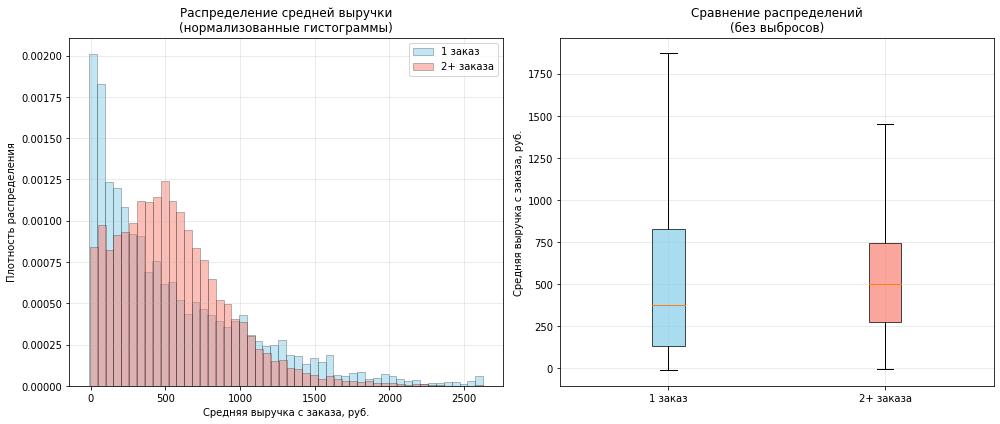

In [21]:
# Построение сравнительных гистограмм
plt.figure(figsize=(14, 6))

# Определяем общие границы для гистограмм
min_revenue = min(single_order_users['avg_revenue_rub'].min(), returning_users['avg_revenue_rub'].min())
max_revenue = max(single_order_users['avg_revenue_rub'].max(), returning_users['avg_revenue_rub'].max())

# Создаем одинаковые интервалы
bins = 50

# Первый график: Гистограммы наложения
plt.subplot(1, 2, 1)
plt.hist(single_order_users['avg_revenue_rub'],
         bins=bins, alpha=0.5, density=True,
         label='1 заказ', color='skyblue', edgecolor='black', linewidth=0.5)
plt.hist(returning_users['avg_revenue_rub'],
         bins=bins, alpha=0.5, density=True,
         label='2+ заказа', color='salmon', edgecolor='black', linewidth=0.5)

plt.xlabel('Средняя выручка с заказа, руб.')
plt.ylabel('Плотность распределения')
plt.title('Распределение средней выручки\n(нормализованные гистограммы)')
plt.legend()
plt.grid(True, alpha=0.3)

# Второй график: Boxplot для сравнения
plt.subplot(1, 2, 2)
box_data = [single_order_users['avg_revenue_rub'], returning_users['avg_revenue_rub']]
box_labels = ['1 заказ', '2+ заказа']

box = plt.boxplot(box_data, labels=box_labels, patch_artist=True, showfliers=False)

# Раскрашиваем boxplot
colors = ['skyblue', 'salmon']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

plt.ylabel('Средняя выручка с заказа, руб.')
plt.title('Сравнение распределений\n(без выбросов)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


С помощью построенных графиков можем ответить на интересующие нас вопросы:
- В каких диапазонах средней выручки концентрируются пользователи из каждой группы?
- Есть ли различия между группами?

1) Больше всего заказов клиенты первой группы (1 заказ через сервис) совершили с довольно маленькой стоимостью: в интервале от 0 до ~400 рублей, наибольшая концентрация пользователей второй группы (2+ заказов) значительно выше: от 400 до ~750 рублей. Следовательно можно сделать вывод, что клиенты второй группы покупают нужные им товары с большой стоимостью, так как уверены в работе сервиса, пользователи же первой группы совершают покупки билетов с низкой ценой, возможно это сезонные покупки, либо купоны/скидки на первый заказ через сервис.

2) По графику "ящик с усами" можно сказать, что различия есть - медиана второй группы выше примерно на 120 рублей (497.56 против 377.37), следовательно клиенты, которые повторно пользуются сервисом делают в среднем более дорогие заказы.

Следующим этапом будет анализ пользователей с различным количеством заказов.

#### 4.2.2 Сравнения распределения показателя средней выручки по двум группам: 2-4 заказа и 5+ заказов
Сравним две группы по распределнию показателя средней выручки:
- Группа 1: пользователи, совершившие 2-4 заказа;
- Группа 2: пользователи, совершившие 5 и более заказов.

Основной задачей данного пункта будет ответ на важный вопрос: есть ли различия по значению средней выручки с заказа между пользователями этих двух групп?

In [22]:
# Распределяем пользователей на группы 2-4 и 5+ заказов
group_2_4 = user_profile_filtered[(user_profile_filtered['orders_cnt']>=2) & (user_profile_filtered['orders_cnt']<=4)]
group_5_plus = user_profile_filtered[user_profile_filtered['orders_cnt']>=5]

print(f"Пользователей с 2-4 заказами: {len(group_2_4)}, доля: {round(len(group_2_4)/len(user_profile_filtered)*100,2)}%")
print(f"Пользователей с 5 и более заказами: {len(group_5_plus)}, доля: {round(len(group_5_plus)/len(user_profile_filtered)*100,2)}%")

# Статистика по средней выручке в каждой группе
print('\nОписательная статистика средней выручки в группе 1 (2-4 заказа):')
print(group_2_4['avg_revenue_rub'].describe().round(2))
print('\nОписательная статистика средней выручки в группе 2 (5+ заказов):')
print(group_5_plus['avg_revenue_rub'].describe().round(2))

Пользователей с 2-4 заказами: 7165, доля: 33.13%
Пользователей с 5 и более заказами: 6068, доля: 28.06%

Описательная статистика средней выручки в группе 1 (2-4 заказа):
count    7165.00
mean      552.56
std       419.49
min        -5.38
25%       219.65
50%       473.96
75%       799.86
max      2628.42
Name: avg_revenue_rub, dtype: float64

Описательная статистика средней выручки в группе 2 (5+ заказов):
count    6068.00
mean      536.19
std       297.48
min         0.00
25%       332.38
50%       513.27
75%       700.12
max      2299.87
Name: avg_revenue_rub, dtype: float64


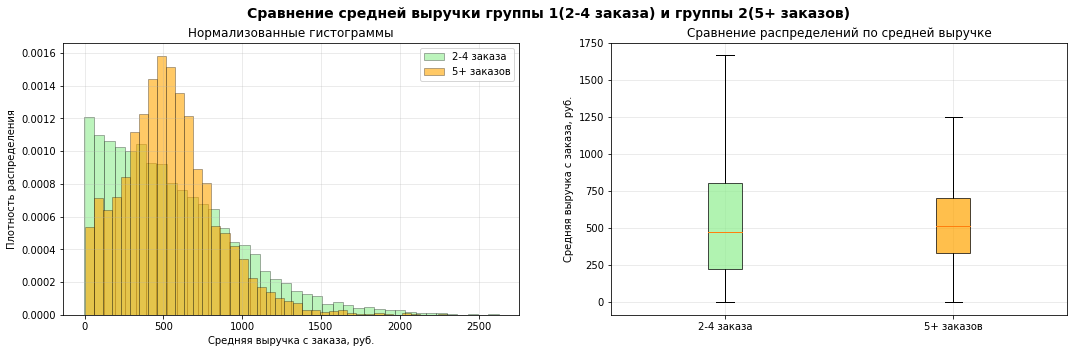

In [23]:
# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
fig.suptitle('Сравнение средней выручки группы 1(2-4 заказа) и группы 2(5+ заказов)', fontsize=14, fontweight='bold')

# 1. Гистограммы
axes[0].hist(group_2_4['avg_revenue_rub'], bins=40, alpha=0.6, density=True,
            label='2-4 заказа', color='lightgreen', edgecolor='black', linewidth=0.5)
axes[0].hist(group_5_plus['avg_revenue_rub'], bins=40, alpha=0.6, density=True,
            label='5+ заказов', color='orange', edgecolor='black', linewidth=0.5)

axes[0].set_xlabel('Средняя выручка с заказа, руб.')
axes[0].set_ylabel('Плотность распределения')
axes[0].set_title('Нормализованные гистограммы')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Boxplot
box_data = [group_2_4['avg_revenue_rub'], group_5_plus['avg_revenue_rub']]
box_labels = ['2-4 заказа', '5+ заказов']

box = axes[1].boxplot(box_data, labels=box_labels, patch_artist=True, showfliers=False)

colors = ['lightgreen', 'orange']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[1].set_ylabel('Средняя выручка с заказа, руб.')
axes[1].set_title('Сравнение распределений по средней выручке')
axes[1].grid(True, alpha=0.3)

Благодаря проведенному анализу статистических показателей и построенным графикам можно ответить на поставленный вопрос.
Показатель медианы для двух групп отличается довольно не сильно, однако у группы 1 (2-4 заказа) большой размах значений, в то время как у пользователей 2-й группы размах меньше.
Концентрация наибольшего числа клиентов в первой группе больше всего на показателях выручки от 0 до 450, далее количество клиентов убывает, у второй группы же показатели другие - основная концетрация покупателей находятся в диапазоне выручки от 400 до 800.
Следовательно, средняя выручка у пользователей группы 5+ заказов немного выше (медиана 513.27 против 473.96 в группе 2-4 заказа).

#### 4.2.3 Анализ влияния среднего количества билетов в заказе на вероятность повторной покупки
Основной задачей текущего этапа является определение взаимосвязи между количеством билетов в заказе и вероятностью возвращения пользователя за повторными покупками.
Разобьем пользователей на сегменты по среднему количеству билетов:
- от 1 до 2 билетов;
- от 2 до 3 билетов;
- от 3 до 5 билетов;
- от 5 билетов и более.

Основной задачей данного этапа будет ответ на следующие вопросы:
- Как распределены пользователи по сегментам - равномерно или сконцентрировано?
- Есть ли сегменты с аномально высокой или низкой долей повторных покупок?

In [24]:
# Общая статистика по среднему количеству билетов в заказе
print(f"Описательная статистика среднего количества билетов в заказе:")
print(user_profile_filtered['avg_tickets'].describe().round(2))
print(f"Мода: {user_profile_filtered['avg_tickets'].mode()[0]}")

Описательная статистика среднего количества билетов в заказе:
count    21626.00
mean         2.74
std          0.92
min          1.00
25%          2.00
50%          2.75
75%          3.10
max         11.00
Name: avg_tickets, dtype: float64
Мода: 3.0


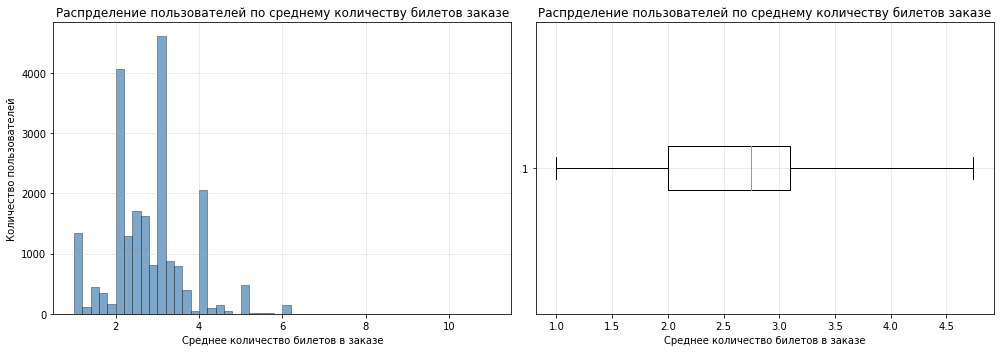

In [25]:
# Изучаем распределение пользователей по avg_tickets
plt.figure(figsize=(14, 5))

# Гистограмма распределения
plt.subplot(1, 2, 1)
plt.hist(user_profile_filtered['avg_tickets'], bins=50, alpha=0.7,
         color='steelblue', edgecolor='black', linewidth=0.5)
plt.xlabel('Среднее количество билетов в заказе')
plt.ylabel('Количество пользователей')
plt.title('Распрделение пользователей по среднему количеству билетов заказе')
plt.grid(True, alpha=0.3)

# Ящик с усами
plt.subplot(1, 2, 2)
plt.boxplot(user_profile_filtered['avg_tickets'], vert=False, showfliers=False)
plt.xlabel('Среднее количество билетов в заказе')
plt.title('Распрделение пользователей по среднему количеству билетов заказе')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Основные наблюдения о распрделении данных:
- Медиана смещена вправо, имеется правый и хвост и довольно большие значения - это нормально - самые популярные показатели количества билетов в заказе;
- Самое востребованное число билетов в заказе в среднем - 3, можно предположить, что это покупка билетов для семейного похода на различные мероприятия, либо поход компании друзей.

In [26]:
# Распределение пользователей на сегменты
ticket_bins = [0, 2, 3, 5, float('inf')]
ticket_labels = ['1-2 билета', '2-3 билета', '3-5 билетов', '5 и более билетов']

# Задаём новое поле в датафрейме - сегмент пользователя по среднему количеству билетов в заказке
user_profile_filtered['ticket_segment'] = pd.cut(user_profile_filtered['avg_tickets'],
                                                  bins=ticket_bins,
                                                  labels=ticket_labels,
                                                  include_lowest=True)

# По новому полю считаем количество пользователей по сегментам (по ср. количеству билетов в заказе)
segment_dist = user_profile_filtered['ticket_segment'].value_counts().sort_index()
print(segment_dist)

1-2 билета           6161
2-3 билета           9931
3-5 билетов          5340
5 и более билетов     194
Name: ticket_segment, dtype: int64



Анализ связи между повторным обращением пользователя к сервису Яндекс Афиша и ср. количеству билетов в заказе

Средние по выборке: возврающтся = 61.19%, лояльные = 28.06%

Детальный анализ по сегментам:
   ticket_segment  total_users  returning_users  loyal_users  return_rate  loyal_rate
       1-2 билета         6161           2467.0        567.0        40.04        9.20
       2-3 билета         9931           7365.0       4047.0        74.16       40.75
      3-5 билетов         5340           3339.0       1445.0        62.53       27.06
5 и более билетов          194             62.0          9.0        31.96        4.64


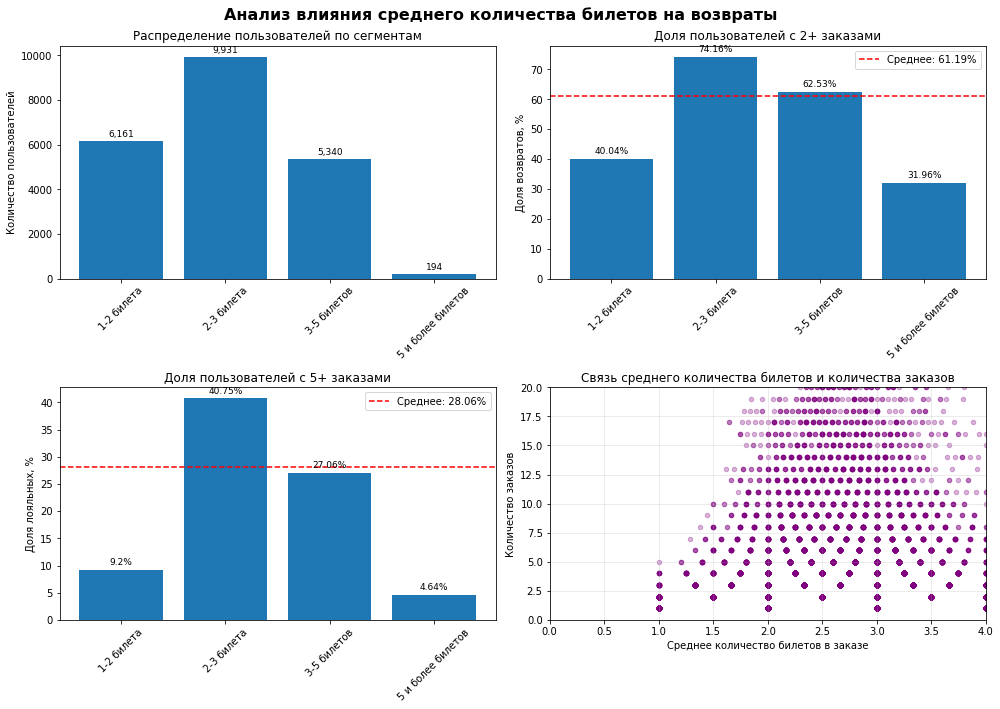

In [27]:
print("\nАнализ связи между повторным обращением пользователя к сервису Яндекс Афиша и ср. количеству билетов в заказе")

segment_analysis = user_profile_filtered.groupby('ticket_segment').agg(
    total_users=('user_id', 'count'),
    returning_users=('is_two', 'sum'),
    loyal_users=('is_five', 'sum')
).reset_index()

# Расчет долей
segment_analysis['return_rate'] = (segment_analysis['returning_users'] /
                                  segment_analysis['total_users'] * 100).round(2)
segment_analysis['loyal_rate'] = (segment_analysis['loyal_users'] /
                                 segment_analysis['total_users'] * 100).round(2)

# Средние значения по всей выборке
avg_return_rate = (user_profile_filtered['is_two'].mean() * 100).round(2)
avg_loyal_rate = (user_profile_filtered['is_five'].mean() * 100).round(2)

print(f"\nСредние по выборке: возврающтся = {avg_return_rate}%, лояльные = {avg_loyal_rate}%")
print("\nДетальный анализ по сегментам:")
print(segment_analysis.to_string(index=False))

# 5. Визуализация результатов
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Анализ влияния среднего количества билетов на возвраты', fontsize=16, fontweight='bold')

# График 1: Распределение по сегментам
bars1 = axes[0, 0].bar(segment_analysis['ticket_segment'], segment_analysis['total_users'])
axes[0, 0].set_title('Распределение пользователей по сегментам')
axes[0, 0].set_ylabel('Количество пользователей')
axes[0, 0].tick_params(axis='x', rotation=45)
for bar in bars1:
    height = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2., height + max(segment_analysis['total_users'])*0.01,
                   f'{int(height):,}', ha='center', va='bottom', fontsize=9)

# График 2: Доля возвратов
bars2 = axes[0, 1].bar(segment_analysis['ticket_segment'], segment_analysis['return_rate'])
axes[0, 1].axhline(y=avg_return_rate, color='r', linestyle='--',
                  label=f'Среднее: {avg_return_rate}%')
axes[0, 1].set_title('Доля пользователей с 2+ заказами')
axes[0, 1].set_ylabel('Доля возвратов, %')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].legend()
for bar in bars2:
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2., height + 1,
                   f'{height}%', ha='center', va='bottom', fontsize=9)

# График 3: Доля лояльных пользователей
bars3 = axes[1, 0].bar(segment_analysis['ticket_segment'], segment_analysis['loyal_rate'])
axes[1, 0].axhline(y=avg_loyal_rate, color='r', linestyle='--',
                  label=f'Среднее: {avg_loyal_rate}%')
axes[1, 0].set_title('Доля пользователей с 5+ заказами')
axes[1, 0].set_ylabel('Доля лояльных, %')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].legend()
for bar in bars3:
    height = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2., height + 0.5,
                   f'{height}%', ha='center', va='bottom', fontsize=9)

# График 4: Связь avg_tickets и количества заказов (scatter plot)
axes[1, 1].scatter(user_profile_filtered['avg_tickets'], user_profile_filtered['orders_cnt'],
                  alpha=0.3, s=20, color='purple')
axes[1, 1].set_xlabel('Среднее количество билетов в заказе')
axes[1, 1].set_ylabel('Количество заказов')
axes[1, 1].set_title('Связь среднего количества билетов и количества заказов')
axes[1, 1].grid(True, alpha=0.3)

# Добавляем линию тренда (ограничиваем диапазон для лучшей видимости)
x_lim = min(user_profile_filtered['avg_tickets'].quantile(0.95), 10)
axes[1, 1].set_xlim(0, x_lim)
axes[1, 1].set_ylim(0, min(user_profile_filtered['orders_cnt'].quantile(0.95), 20))

plt.tight_layout()
plt.show()

Полагаясь на данные графики можем ответить на поставленные в начале подпункта вопросы:

1) Пользователи разделены по сегментам сконцентрировано - преобладают клиенты, у которых в среднем 2-3 билета в заказе.

2) Присутствуют сегменты с аномально высокой долей повторных покупок: около 40% пользователей из сегмента "2-3 билета" совершают 5+ заказов, следовательно возвращаются к услугам сервиса довольно часто. Пользователи из сегмента "5 и более билетов" довольно часто не возвращаются на сайт за повторными покупками, возможно это были "одноразовые" покупки на большую компанию.

### 4.3 Исследование временных характеристик первого заказа и их влияния на повторные покупки
В данном разделе изучим временные параметры, связанные с первым заказом пользователя.

#### 4.3.1 Влияние дня недели первой покупки
На данном этапе важно узнать: влияет ли день недели, в которую совершена первая покупка, на вероятность возврата клиента?

Анализ взаимосвязи дня недели первой покупки и повторной покупки пользователем
Средняя доля возвратов по выборке: 61.19%

Статистика по дням недели:
first_order_weekday  total_users  returning_users  return_rate
             Friday         3260           1950.0        59.82
             Monday         2928           1841.0        62.88
           Saturday         3323           2083.0        62.68
             Sunday         2774           1660.0        59.84
           Thursday         3108           1841.0        59.23
            Tuesday         3174           1959.0        61.72
          Wednesday         3059           1899.0        62.08


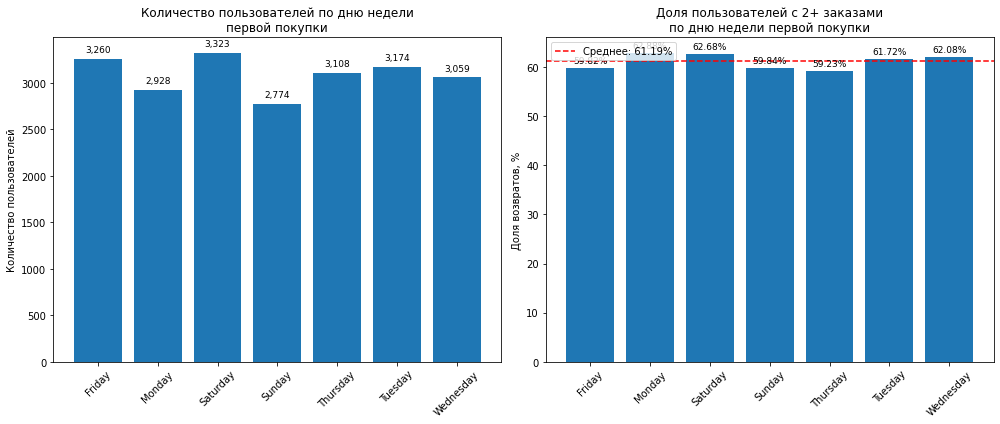


Анализ различий
Самое высокое количество вернувшихся пользователей: Monday - 62.88% (2928 пользователей)
Самый низкое количество вернувшихся пользователей: Thursday - 59.23% (3108 пользователей)

ВЫВОД: День недели НЕ оказывает существенного влияния на вероятность возврата.
       Различия между днями незначительные.


In [28]:
# Выделяем день недели из даты первого заказа
user_profile_filtered['first_order_weekday'] = user_profile_filtered['first_order_dt'].dt.day_name()

# Анализируем по дням недели
weekday_analysis = user_profile_filtered.groupby('first_order_weekday').agg(
    total_users=('user_id', 'count'),
    returning_users=('is_two', 'sum')
).reset_index()

# Считаем доли
weekday_analysis['return_rate'] = (weekday_analysis['returning_users'] / weekday_analysis['total_users'] * 100).round(2)

# Средняя доля возвратов по всей выборке
avg_return_rate = (user_profile_filtered['is_two'].mean() * 100).round(2)

print("Анализ взаимосвязи дня недели первой покупки и повторной покупки пользователем")
print(f"Средняя доля возвратов по выборке: {avg_return_rate}%")
print("\nСтатистика по дням недели:")
print(weekday_analysis.to_string(index=False))

# Визуализация
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# График 1: Количество пользователей
bars1 = ax1.bar(weekday_analysis['first_order_weekday'], weekday_analysis['total_users'])
ax1.set_title('Количество пользователей по дню недели\nпервой покупки')
ax1.set_ylabel('Количество пользователей')
ax1.tick_params(axis='x', rotation=45)

# Добавляем подписи
for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 50,
            f'{int(height):,}', ha='center', va='bottom', fontsize=9)

# График 2: Доля возвратов
bars2 = ax2.bar(weekday_analysis['first_order_weekday'], weekday_analysis['return_rate'])
ax2.axhline(y=avg_return_rate, color='red', linestyle='--',
           label=f'Среднее: {avg_return_rate}%')
ax2.set_title('Доля пользователей с 2+ заказами\nпо дню недели первой покупки')
ax2.set_ylabel('Доля возвратов, %')
ax2.tick_params(axis='x', rotation=45)
ax2.legend()

# Добавляем подписи
for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 0.5,
            f'{height}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Анализ различий
print("\nАнализ различий")
max_rate_day = weekday_analysis.loc[weekday_analysis['return_rate'].idxmax()]
min_rate_day = weekday_analysis.loc[weekday_analysis['return_rate'].idxmin()]

print(f"Самое высокое количество вернувшихся пользователей: {max_rate_day['first_order_weekday']} - {max_rate_day['return_rate']}% ({max_rate_day['total_users']} пользователей)")
print(f"Самый низкое количество вернувшихся пользователей: {min_rate_day['first_order_weekday']} - {min_rate_day['return_rate']}% ({min_rate_day['total_users']} пользователей)")

# Проверяем, отличается ли самый высокий показатель от среднего
if max_rate_day['return_rate'] > avg_return_rate + 2:  # порог 2%
    print(f"\nВЫВОД: День недели ВЛИЯЕТ на вероятность возврата.")
    print(f"       Пользователи, совершившие первую покупку в {max_rate_day['first_order_weekday']},")
    print(f"       возвращаются на {max_rate_day['return_rate'] - avg_return_rate:.1f}% чаще среднего.")
else:
    print(f"\nВЫВОД: День недели НЕ оказывает существенного влияния на вероятность возврата.")
    print(f"       Различия между днями незначительные.")

Больше всего пользователей совершают первый заказ в субботу (3 323) и пятницу (3 260), что может быть связано с планированием отдыха на выходных. Однако существенного влияния дня недели первого заказа на повторную покупку не наблюдается: доля возвратов колеблется от 59.23% (четверг) до 62.88% (понедельник).

#### 4.3.2 Влияние среднего интервала между заказами
На данном этапе исследуем, как средний интервал между заказами влияет на вероятность повторного заказа.

Пользователей с 2-4 заказами: 7,165
Пользователей с 5+ заказами: 6,068

Описательная статистика полученных групп по ср. количеству дней между покупками
Группа 2-4 заказа:
  Среднее: 21.5 дней
  Медиана: 9.0 дней
  Минимум: 0.0 дней
  Максимум: 148.0 дней

Группа 5+ заказов:
  Среднее: 10.0 дней
  Медиана: 8.3 дней
  Минимум: 0.0 дней
  Максимум: 37.5 дней


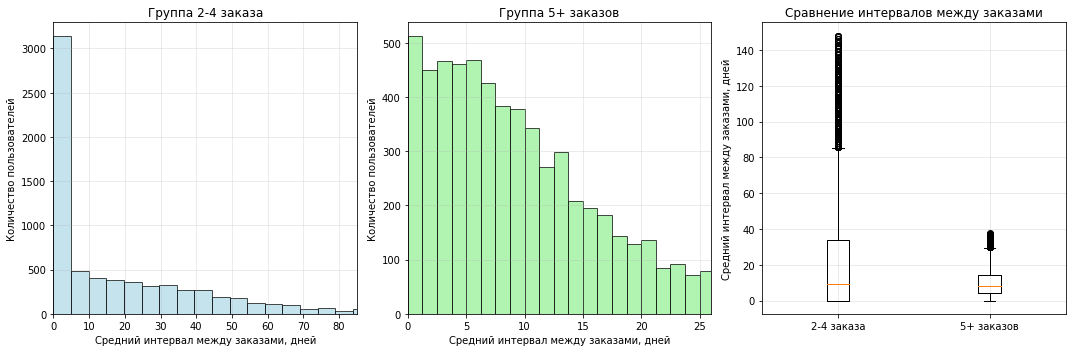

Анализ сегментов по интервалам между заказами

Влияние интервала между заказами на лояльность:
interval_segment  total_users  loyal_users  loyal_rate
          <1 мес         8377       5676.0       67.76
         1-2 мес         1461        132.0        9.03
         2-3 мес          396          0.0        0.00
         3-6 мес          305          0.0        0.00
        6-12 мес            0          0.0         NaN
         >1 года            0          0.0         NaN


posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


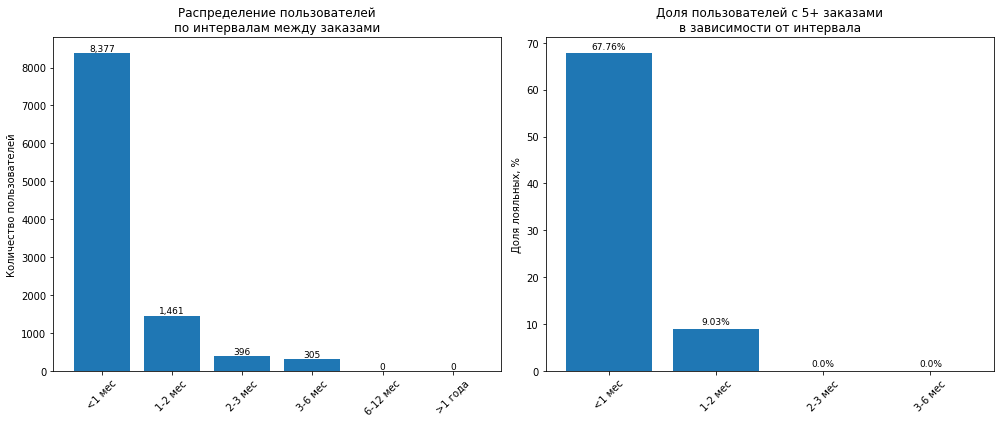

In [29]:
# Создаем группы пользователей
group_2_4 = user_profile_filtered[(user_profile_filtered['orders_cnt'] >= 2) & (user_profile_filtered['orders_cnt'] <= 4)]
group_5_plus = user_profile_filtered[user_profile_filtered['orders_cnt'] >= 5]

print(f"Пользователей с 2-4 заказами: {len(group_2_4):,}")
print(f"Пользователей с 5+ заказами: {len(group_5_plus):,}")

# Анализируем avg_days_btwn для каждой группы
print("\nОписательная статистика полученных групп по ср. количеству дней между покупками")

print("Группа 2-4 заказа:")
if len(group_2_4) > 0:
    print(f"  Среднее: {group_2_4['avg_days_btwn'].mean():.1f} дней")
    print(f"  Медиана: {group_2_4['avg_days_btwn'].median():.1f} дней")
    print(f"  Минимум: {group_2_4['avg_days_btwn'].min():.1f} дней")
    print(f"  Максимум: {group_2_4['avg_days_btwn'].max():.1f} дней")
else:
    print("  Нет данных")

print("\nГруппа 5+ заказов:")
if len(group_5_plus) > 0:
    print(f"  Среднее: {group_5_plus['avg_days_btwn'].mean():.1f} дней")
    print(f"  Медиана: {group_5_plus['avg_days_btwn'].median():.1f} дней")
    print(f"  Минимум: {group_5_plus['avg_days_btwn'].min():.1f} дней")
    print(f"  Максимум: {group_5_plus['avg_days_btwn'].max():.1f} дней")
else:
    print("  Нет данных")

# Визуализация
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Гистограмма для группы 2-4 заказа
if len(group_2_4) > 0:
    axes[0].hist(group_2_4['avg_days_btwn'].dropna(), bins=30, alpha=0.7,
                color='lightblue', edgecolor='black')
    axes[0].set_xlabel('Средний интервал между заказами, дней')
    axes[0].set_ylabel('Количество пользователей')
    axes[0].set_title('Группа 2-4 заказа')
    axes[0].grid(True, alpha=0.3)
    axes[0].set_xlim(0, group_2_4['avg_days_btwn'].quantile(0.95))

# Гистограмма для группы 5+ заказов
if len(group_5_plus) > 0:
    axes[1].hist(group_5_plus['avg_days_btwn'].dropna(), bins=30, alpha=0.7,
                color='lightgreen', edgecolor='black')
    axes[1].set_xlabel('Средний интервал между заказами, дней')
    axes[1].set_ylabel('Количество пользователей')
    axes[1].set_title('Группа 5+ заказов')
    axes[1].grid(True, alpha=0.3)
    axes[1].set_xlim(0, group_5_plus['avg_days_btwn'].quantile(0.95))

# Сравнительный boxplot
if len(group_2_4) > 0 and len(group_5_plus) > 0:
    plot_data = [group_2_4['avg_days_btwn'].dropna(), group_5_plus['avg_days_btwn'].dropna()]
    plot_labels = ['2-4 заказа', '5+ заказов']

    axes[2].boxplot(plot_data, labels=plot_labels)
    axes[2].set_ylabel('Средний интервал между заказами, дней')
    axes[2].set_title('Сравнение интервалов между заказами')
    axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Анализ сегментов по интервалам
print("Анализ сегментов по интервалам между заказами")

# Создаем сегменты для пользователей с повторными заказами
repeat_users = user_profile_filtered[user_profile_filtered['orders_cnt'] >= 2].copy()

# Убираем пропуски
repeat_users_clean = repeat_users.dropna(subset=['avg_days_btwn'])

# Создаем сегменты
interval_bins = [0, 30, 60, 90, 180, 365, float('inf')]
interval_labels = ['<1 мес', '1-2 мес', '2-3 мес', '3-6 мес', '6-12 мес', '>1 года']

repeat_users_clean['interval_segment'] = pd.cut(repeat_users_clean['avg_days_btwn'],
                                               bins=interval_bins,
                                               labels=interval_labels)

# Анализируем
interval_analysis = repeat_users_clean.groupby('interval_segment').agg(
    total_users=('user_id', 'count'),
    loyal_users=('is_five', 'sum')
).reset_index()

# Считаем доли
interval_analysis['loyal_rate'] = (interval_analysis['loyal_users'] / interval_analysis['total_users'] * 100).round(2)

print("\nВлияние интервала между заказами на лояльность:")
print(interval_analysis.to_string(index=False))

# Визуализация зависимости
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# График 1: Распределение по сегментам
bars1 = ax1.bar(interval_analysis['interval_segment'], interval_analysis['total_users'])
ax1.set_title('Распределение пользователей\nпо интервалам между заказами')
ax1.set_ylabel('Количество пользователей')
ax1.tick_params(axis='x', rotation=45)

for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 5,
            f'{int(height):,}', ha='center', va='bottom', fontsize=9)

# График 2: Доля лояльных пользователей
bars2 = ax2.bar(interval_analysis['interval_segment'], interval_analysis['loyal_rate'])
ax2.set_title('Доля пользователей с 5+ заказами\nв зависимости от интервала')
ax2.set_ylabel('Доля лояльных, %')
ax2.tick_params(axis='x', rotation=45)

for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 0.5,
            f'{height}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

Вывод: медианный интервал между заказами в группе 2-4 заказа составляет 9.0 дня (среднее 21.5), в группе 5+ заказов 8.3 дня (среднее 10.0). Различие медиан невелико, но среднее значение и разброс заметно ниже у лояльных пользователей: они возвращаются регулярнее. Стоит поощрять более частые покупки.

### 4.4 Корреляционный анализ количества покупок и признаков пользователя
#### 4.4.1 Корреляционный анализ
При помощи матрицы корреляции phi_k изучим наибольшую связь количества покупок и признаков пользователя.

Анализируем 6 признаков с orders_cnt (общее количество заказов)
Размер выборки: 21,626 пользователей

Проверка распределения количества заказов
Распределение заказов:
  1 заказ(ов): 8,393 (38.8%)
  2 заказ(ов): 3,595 (16.6%)
  3 заказ(ов): 2,173 (10.0%)
  4 заказ(ов): 1,397 (6.5%)
  5 заказ(ов): 977 (4.5%)
  6 заказ(ов): 699 (3.2%)
  7 заказ(ов): 528 (2.4%)
  8 заказ(ов): 458 (2.1%)
  9 заказ(ов): 382 (1.8%)
  10 заказ(ов): 285 (1.3%)

Преобладающее значение: 1 заказ(ов) (38.8%)

Расчёт корреляции phik
Используем числовые значения общего числа заказов

Корреляция с общим числом заказов (исходные данные):
----------------------------------------
avg_tickets              : 0.231 (умеренная)
avg_revenue_rub          : 0.226 (умеренная)
region_name              : 0.115 (умеренная)
device_type_canonical    : 0.033 (очень слабая)
service_name             : 0.027 (очень слабая)
event_type_main          : 0.020 (очень слабая)

Создаем сегменты, в зависимости от количества заказов и повторяем а

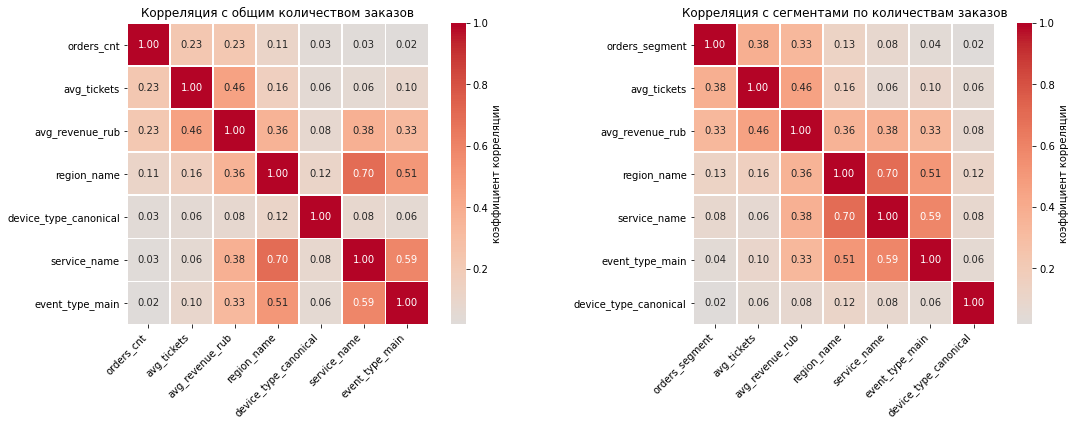


ОТВЕТ НА ВОПРОС

Какие признаки наиболее связаны с количеством заказов (orders_cnt)?
--------------------------------------------------

Рейтинг признаков по силе связи с количеством заказов:
--------------------------------------------------
1. avg_tickets              
   Числовая orders_cnt: 0.231
   Категориальная:      0.384
   Максимальная:        0.384 (СИЛЬНАЯ)

2. avg_revenue_rub          
   Числовая orders_cnt: 0.226
   Категориальная:      0.329
   Максимальная:        0.329 (СИЛЬНАЯ)

3. region_name              
   Числовая orders_cnt: 0.115
   Категориальная:      0.126
   Максимальная:        0.126 (УМЕРЕННАЯ)

4. service_name             
   Числовая orders_cnt: 0.027
   Категориальная:      0.083
   Максимальная:        0.083 (СЛАБАЯ)

5. event_type_main          
   Числовая orders_cnt: 0.020
   Категориальная:      0.042
   Максимальная:        0.042 (ОЧЕНЬ СЛАБАЯ)

6. device_type_canonical    
   Числовая orders_cnt: 0.033
   Категориальная:      0.017
   Максимал

In [30]:
# Подготовка данных для анализа
analysis_df = user_profile_filtered.copy()

# Выбираем признаки для анализа
features = [
    'device_type_canonical',
    'region_name',
    'service_name',
    'event_type_main',
    'avg_revenue_rub',
    'avg_tickets',
    'orders_cnt'
]

corr_data = analysis_df[features].copy()

print(f"Анализируем {len(features)-1} признаков с orders_cnt (общее количество заказов)")
print(f"Размер выборки: {len(corr_data):,} пользователей")

# Проверяем распределение orders_cnt
print("\nПроверка распределения количества заказов")
orders_dist = corr_data['orders_cnt'].value_counts().sort_index()
print("Распределение заказов:")
for orders, count in orders_dist.head(10).items():
    pct = count / len(corr_data) * 100
    print(f"  {orders} заказ(ов): {count:,} ({pct:.1f}%)")

# Проверяем преобладание одного значения
dominant_value = orders_dist.index[0]
dominant_count = orders_dist.iloc[0]
dominant_pct = (dominant_count / len(corr_data)) * 100

print(f"\nПреобладающее значение: {dominant_value} заказ(ов) ({dominant_pct:.1f}%)")

# Расчет корреляции phi_k для исходных данных
print("\nРасчёт корреляции phik")
print("Используем числовые значения общего числа заказов")

# Указываем интервальные колонки
interval_cols = ['avg_revenue_rub', 'avg_tickets', 'orders_cnt']

# Рассчитываем матрицу корреляции
phi_matrix = corr_data.phik_matrix(interval_cols=interval_cols)

# Выводим корреляции с orders_cnt
print("\nКорреляция с общим числом заказов (исходные данные):")
print("-" * 40)

orders_corr = phi_matrix['orders_cnt'].sort_values(ascending=False)

for feature, corr in orders_corr.items():
    if feature != 'orders_cnt':
        if corr > 0.3:
            strength = "сильная"
        elif corr > 0.1:
            strength = "умеренная"
        elif corr > 0.05:
            strength = "слабая"
        else:
            strength = "очень слабая"
        print(f"{feature:25}: {corr:.3f} ({strength})")

# Создаем сегменты и повторяем анализ
print("\nСоздаем сегменты, в зависимости от количества заказов и повторяем анализ")

# Создаем сегменты как указано в задании
def create_segment(orders):
    if orders == 1:
        return '1 заказ'
    elif 2 <= orders <= 4:
        return '2-4 заказа'
    else:  # 5 и более
        return '5+ заказов'

corr_data['orders_segment'] = corr_data['orders_cnt'].apply(create_segment)

# Проверяем распределение по сегментам
print("\nРаспределение по сегментам:")
segment_dist = corr_data['orders_segment'].value_counts()
for segment, count in segment_dist.items():
    pct = count / len(corr_data) * 100
    print(f"  {segment}: {count:,} ({pct:.1f}%)")

# Удаляем числовую orders_cnt для анализа с сегментами
segment_data = corr_data.drop('orders_cnt', axis=1)

# Указываем интервальные колонки (без orders_cnt)
interval_cols_segment = ['avg_revenue_rub', 'avg_tickets']

# Рассчитываем матрицу корреляции для сегментов
phi_matrix_segment = segment_data.phik_matrix(interval_cols=interval_cols_segment)

# Выводим корреляции с orders_segment
print("\nКорреляция с сегментами:")
print("-" * 40)

segment_corr = phi_matrix_segment['orders_segment'].sort_values(ascending=False)

for feature, corr in segment_corr.items():
    if feature != 'orders_segment':
        if corr > 0.3:
            strength = "сильная"
        elif corr > 0.1:
            strength = "умеренная"
        elif corr > 0.05:
            strength = "слабая"
        else:
            strength = "очень слабая"
        print(f"{feature:25}: {corr:.3f} ({strength})")

# Визуализация тепловой карты
print("\nВизуализация результатов")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Тепловая карта для исходных данных
sorted_features = orders_corr.index.tolist()
sorted_matrix = phi_matrix.loc[sorted_features, sorted_features]

sns.heatmap(sorted_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5, ax=ax1,
            cbar_kws={'label': 'коэффициент корреляции'})
ax1.set_title('Корреляция с общим количеством заказов', fontsize=12)
plt.sca(ax1)  # Устанавливаем текущую ось
plt.xticks(rotation=45, ha='right')

# Тепловая карта для сегментов
sorted_features_segment = segment_corr.index.tolist()
sorted_matrix_segment = phi_matrix_segment.loc[sorted_features_segment, sorted_features_segment]

sns.heatmap(sorted_matrix_segment, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5, ax=ax2,
            cbar_kws={'label': 'коэффициент корреляции'})
ax2.set_title('Корреляция с сегментами по количествам заказов', fontsize=12)
plt.sca(ax2)  # Устанавливаем текущую ось
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

# Ответ на вопрос
print("\n" + "="*60)
print("ОТВЕТ НА ВОПРОС")
print("="*60)

print("\nКакие признаки наиболее связаны с количеством заказов (orders_cnt)?")
print("-" * 50)

# Определяем наиболее значимые признаки
top_features = []

# Смотрим оба анализа и берем максимальную корреляцию
for feature in ['device_type_canonical', 'region_name', 'service_name',
                'event_type_main', 'avg_revenue_rub', 'avg_tickets']:

    corr_num = orders_corr.get(feature, 0)
    corr_seg = segment_corr.get(feature, 0)

    # Берем максимальную по модулю корреляцию
    max_corr = max(abs(corr_num), abs(corr_seg))
    top_features.append((feature, max_corr, corr_num, corr_seg))

# Сортируем по силе связи
top_features.sort(key=lambda x: x[1], reverse=True)

print("\nРейтинг признаков по силе связи с количеством заказов:")
print("-" * 50)

for i, (feature, max_corr, corr_num, corr_seg) in enumerate(top_features, 1):
    if max_corr > 0.3:
        strength = "СИЛЬНАЯ"
    elif max_corr > 0.1:
        strength = "УМЕРЕННАЯ"
    elif max_corr > 0.05:
        strength = "СЛАБАЯ"
    else:
        strength = "ОЧЕНЬ СЛАБАЯ"

    print(f"{i}. {feature:25}")
    print(f"   Числовая orders_cnt: {corr_num:.3f}")
    print(f"   Категориальная:      {corr_seg:.3f}")
    print(f"   Максимальная:        {max_corr:.3f} ({strength})")
    print()

# Ключевые выводы
print("\n" + "="*60)
print("КЛЮЧЕВЫЕ ВЫВОДЫ")
print("="*60)

print("\n1. НАИБОЛЕЕ СВЯЗАННЫЕ ПРИЗНАКИ С КОЛИЧЕСТВОМ ЗАКАЗОВ:")
print("   (признаки с умеренной или сильной связью, phi_k > 0.1)")

strong_features = [(f, mc) for f, mc, _, _ in top_features if mc > 0.1]

if strong_features:
    for feature, max_corr in strong_features:
        print(f"   • {feature}: phi_k = {max_corr:.3f}")
else:
    print("   Нет признаков с умеренной или сильной связью")

print("\n2. СЛАБО СВЯЗАННЫЕ ПРИЗНАКИ:")
weak_features = [(f, mc) for f, mc, _, _ in top_features if mc <= 0.1]

for feature, max_corr in weak_features:
    print(f"   • {feature}: phi_k = {max_corr:.3f} (слабая связь)")

print("\n3. ВЛИЯНИЕ ПРЕОБЛАДАНИЯ ОДНОГО ЗНАЧЕНИЯ:")
print(f"   • {dominant_pct:.1f}% пользователей имеют {dominant_value} заказ")
print("   • Это может занижать корреляционные коэффициенты")
print("   • Использование категоризации (сегментов) помогает выявить связи")

print("\n4. ОТВЕТ НА ВОПРОС:")
print("   Признаки наиболее связанные с количеством заказов:")
if strong_features:
    for feature, max_corr in strong_features:
        print(f"   - {feature} (phi_k = {max_corr:.3f})")
else:
    print("   - Все связи слабые, нет явно выраженных зависимостей")

Наиболее связаны с количеством заказов (коэффициент phik, в скобках для сегментов по числу заказов):
- `avg_tickets`, среднее количество билетов в заказе: 0.231 (0.384);
- `avg_revenue_rub`, средняя выручка с заказа: 0.226 (0.329);
- `region_name`, регион первого заказа: 0.115 (0.126).

Следовательно, количество покупок пользователя связано с «размером» его покупок: средним количеством билетов и средним чеком. Тип устройства, билетный оператор и тип мероприятия связаны слабо (коэффициенты не превышают 0.09).

## 5. Общие выводы и рекомендации

**Информация о полученных данных:** основной датасет загружен из базы данных и содержит информацию о заказах на платформе «Яндекс Афиша». Выполнена предобработка:
- перевод выручки в рубли;
- проверка пропущенных и некорректных значений;
- удаление технических дубликатов заказов и записей с отрицательной выручкой (возвраты);
- оптимизация типов данных;
- фильтрация `revenue_rub` и `orders_cnt` по 99-му перцентилю.

Подготовлен профиль пользователя:
- идентификатор пользователя;
- дата и время первого и последнего заказов;
- регион, билетный сервис, тип устройства и тип мероприятия первого заказа;
- общее количество заказов, средняя выручка, среднее количество билетов в заказе;
- среднее количество дней между заказами;
- два бинарных признака: 2+ заказа и 5+ заказов.

**Основные результаты анализа:**

1) В выборке 21 626 пользователей: с одним заказом 8 393 (38.81%), с двумя и более 13 233 (61.19%).

2) Признаки первого заказа и возврат на платформу. Чаще возвращаются пользователи, начавшие с выставок (64.0%), театра (63.3%) и концертов (61.7%); реже со спортивных мероприятий (55.6%). Пользователи десктопа возвращаются чаще (63.7%), чем пользователи мобильных устройств (60.7%), хотя мобильных пользователей значительно больше. День недели первого заказа влияет слабо (доля возвратов от 59.2% до 62.9%).

3) Гипотезы. Первая гипотеза (спорт возвращает чаще концертов) не подтвердилась. Вторая (в активных регионах возврат выше) подтверждается лишь слабо: разница 5.4 п.п. между группами регионов значима при объединении пользователей, но корреляция размера региона и доли возвратов слабая (r = 0.12), надёжного вывода сделать нельзя.

4) Количество билетов и выручка. Наибольшая доля возвратов у пользователей, покупающих в среднем 2-3 билета (74.2%), наименьшая у покупающих 1-2 билета (40.0%) и 5 и более билетов (32.0%). Среднее количество билетов и средняя выручка умеренно связаны с количеством заказов (phik около 0.23).

5) Интервал между заказами. Лояльные пользователи (5+ заказов) возвращаются регулярнее: среднее число дней между заказами 10.0 против 21.5 в группе 2-4 заказа.

**Бизнес-рекомендации:**

- Поощрять клиентов, часто оформляющих заказы (программы лояльности, бонусы за повторные покупки), для удержания их на платформе;
- Уделять особое внимание клиентам с большим средним чеком и 2-3 билетами в заказе: именно в этих сегментах наиболее высокая доля возвратов;
- При привлечении новых пользователей делать упор на мероприятия с высокой долей возвратов (выставки, театр, концерты), а для спорта и «ёлок» разработать отдельные механики удержания.